# Phanuel Ayuka
# ADM No. 224078

# MIR calibration of soil properties

**Objectives**
1. Develop and validate MIR calibration models for soil organic carbon  and pH using wet-chemistry reference measurements.
2. Compare statistical and machine-learning algorithms under different MIR spectral preprocessing procedures.

## 0. Setup

### Imports

In [1]:
import importlib
import json
import os
import sys
import time
import warnings
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from scipy.signal import savgol_filter
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.cluster import KMeans
from sklearn.compose import TransformedTargetRegressor
from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import ElasticNet, Ridge
from sklearn.metrics import adjusted_rand_score, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.svm import SVR

try:
    from pyproj import Transformer
    PYPROJ_AVAILABLE = True
except ImportError:
    PYPROJ_AVAILABLE = False


### 0.2 Configuration
**This is the only cell you should need to edit.** All choices that affect the science are here, with a comment on each. Change a value, re-run from the top, and everything downstream follows.

Points worth a decision:
- `SPECTRA_PATH` / `WET_CHEMISTRY_PATH`: point these at your full files (`.xlsx` or `.csv`).
- `WAVENUMBER_RANGES_TO_INTERPOLATE`: the CO2 region (about 2280 to 2400 cm-1) carries atmospheric noise, not soil information. It is bridged by a straight line, which keeps the wavenumber axis regular (important for derivatives).
- `WAVENUMBER_RANGES_TO_REMOVE`: the noisy detector edge. Step 2 plots the spread of the data per wavenumber so you can judge these ranges yourself.
- `DOWNSAMPLE_STEP`: keeps every n-th wavenumber. With the full data, 2 roughly halves the run time with little loss, because MIR instruments rarely resolve finer than 4 cm-1.
- `ALGORITHMS_TO_RUN` / `PREPROCESSINGS_TO_RUN`: the full grid is large. For a first pass, try `["pls", "ridge"]` and a few preprocessings, then widen. Results are cached, so re-runs skip finished combinations.

In [2]:

OUTPUT_DIR = Path("outputs")
TARGET_COLUMNS = ["orgc", "ph_h2o"] # soil organic carbon and pH


TARGET_PHYSICAL_LIMITS = {
    "orgc": (0.0, 60.0),
    "ph_h2o": (2.5, 11.0),
}

# identifiers and depth
LAYER_SUFFIX_TO_DEPTH_CLASS = {"T": "topsoil", "S": "subsoil"}
EXPECTED_DEPTH_LIMITS_CM = {"topsoil": (0, 20), "subsoil": (20, 50)}

# coordinates (wet-chem file: X = longitude, Y = latitude, degrees)
LONGITUDE_COLUMN = "X"
LATITUDE_COLUMN = "Y"
EXPECTED_LONGITUDE_RANGE = (33.5, 42.0)   # Kenya, with a small margin
EXPECTED_LATITUDE_RANGE = (-5.0, 5.5)

# spectra constants
MAXIMUM_MISSING_FRACTION_PER_SPECTRUM = 0.05
WAVENUMBER_RANGES_TO_INTERPOLATE = [(2280.0, 2400.0)]
WAVENUMBER_RANGES_TO_REMOVE = [(499.0, 600.0)]
DOWNSAMPLE_STEP = 2
SPECTRAL_OUTLIER_COMPONENTS = 5
SPECTRAL_OUTLIER_PROBABILITY = 0.999

# spatial blocks
NUMBER_OF_SPATIAL_BLOCKS = 8
MINIMUM_PLOTS_PER_BLOCK = 3
PRIMARY_BLOCK_SEED = 42
STABILITY_BLOCK_SEEDS = [7, 123, 2024, 99] # extra block layouts, used only for the best models
MINIMUM_CALIBRATION_PLOTS = 24

# preprocessing and models
PREPROCESSINGS_TO_RUN = ["raw", "snv", "msc", "sg1", "sg2", "snv_sg1"]
# Two-stage design: Stage A compares the preprocessings with ONE reference model; Stage B compares the candidate
# algorithms on the best preprocessing(s) only.
PREPROCESSING_SCREENING_ALGORITHM = "pls"
ALGORITHMS_TO_RUN = ["pls", "ridge", "svr", "random_forest"]      # the 4 candidate models
STAGE_B_PREPROCESSING_COUNT = 1     # 1 = only the best preprocessing goes to Stage B; 2 = the best two (bigger, interaction table)
SAVITZKY_GOLAY_WINDOW = 11          # number of points, must be odd
SAVITZKY_GOLAY_POLYNOMIAL = 2
LOG_TRANSFORM_TARGETS = []          # e.g. ["orgc"] if Step 2 shows strong right skew
MINIMUM_SAMPLES_PER_DEPTH_CLASS = 10   # below this, depth class is not used as a model input

# validation
OUTER_FOLDS = 8
INNER_FOLDS = 3
USE_RESULT_CACHE = True
RUN_SEPARATE_DEPTH_MODELS = True

# final models and prediction
DOMAIN_PCA_COMPONENTS = 5
DOMAIN_DISTANCE_PERCENTILE = 95
PREDICTION_INTERVAL_COVERAGE = 0.90
MODEL_VERSION = "v0.1"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("configuration loaded; outputs go to", OUTPUT_DIR.resolve())

configuration loaded; outputs go to /Volumes/FILES/Strathmore DSA/Module 4 Jul_Sep 2026/DSA 8401 Applied Machine Learning in Data Science/Capstone Project/outputs


### 0.3 Helper functions used throughout
Three small helpers:
- `record_issue` writes every data problem to the **issue register** (and prints it), so nothing is hidden.
- `normalise_identifier` cleans ID text: strips spaces, upper-cases, and turns `""`, `"nan"`, `"none"` into real missing values. Dirty IDs are the most common reason a join silently loses rows.

In [3]:
def normalise_identifier(text_series):
    # Strip spaces, upper-case, and convert empty/placeholder text to real missing values.
    cleaned = text_series.astype(str).str.strip().str.upper()
    placeholders = ["", "NAN", "NONE", "NA", "<NA>", "NULL"]
    return cleaned.where(~cleaned.isin(placeholders), np.nan)


def column_name_is_number(column_name):
    # Wavenumber columns have numeric names (499.2, 501.3, ...). Excel gives floats, CSV gives text.
    try:
        float(column_name)
    except (TypeError, ValueError):
        return False
    return True


print("helpers defined")

helpers defined


# Step 1: Load and join the data

1. The spectra and the wet chemistry data are in different files.
2. The join key is `layer_id` (for example `KE001-1-1T`) as is unique per sample and its last letter gives the depth: `T` = topsoil (0 to 20 cm), `S` = subsoil (20 to 50 cm).
3. `plot_code` is `layer_id` without the last letter and is what groups topsoil and subsoil of the same place.
4. Only the wet-chem file has coordinates (`X`, `Y`).

### 1.1 Load both data files

In [4]:
raw_spectra_df = pd.read_excel("spectral_data_kenya.xlsx")
print("spectra:", raw_spectra_df.shape, "(rows, columns)")

spectra: (790, 1714) (rows, columns)


In [5]:
raw_wet_chem_df = pd.read_excel("wet_chem_analysis.xlsx")
print("wet chemistry:", raw_wet_chem_df.shape, "(rows, columns)")

wet chemistry: (121, 69) (rows, columns)


### 1.2 Separating wavenumber columns from metadata columns in the spectra data
Any column whose *name* is a number (499.2, 501.3, ...) is a spectral measurement; everything else is metadata. 
The number of wavenumber columns should range about 499 to 3996.

In [6]:
wavenumber_column_names = [name for name in raw_spectra_df.columns if column_name_is_number(name)]
metadata_column_names = [name for name in raw_spectra_df.columns if not column_name_is_number(name)]

wavenumber_values = np.array([float(name) for name in wavenumber_column_names])
print("wavenumber columns:", len(wavenumber_column_names))
print("range:", wavenumber_values.min(), "to", wavenumber_values.max(), "cm-1")
print("metadata columns :", metadata_column_names)

wavenumber columns: 1703
range: 499.2 to 3996.0 cm-1
metadata columns : ['gid', 'country_name', 'country_code', 'psu_code', 'plot_code', 'layer_id', 'scan_date', 'qr_code', 'upper_depth', 'lower_depth', 'soil_depth']


In [7]:
# Spectral values: force numbers, turn text and infinity into missing and report how many.
spectral_part_of_raw_df = raw_spectra_df[wavenumber_column_names]
missing_before_conversion = int(spectral_part_of_raw_df.isna().sum().sum())

spectra_values_df = spectral_part_of_raw_df.apply(pd.to_numeric, errors="coerce")
spectra_values_df = spectra_values_df.replace([np.inf, -np.inf], np.nan)
cells_made_missing = int(spectra_values_df.isna().sum().sum()) - missing_before_conversion
if cells_made_missing > 0:
    print("Non-numeric or infinite values inside spectral columns", cells_made_missing, "converted to missing")

All spectra values are numbers and none has been converted from text

In [8]:
# Wavenumber order
spectra_values_df.columns = wavenumber_values
if not np.all(np.diff(wavenumber_values) > 0):
    sort_order = np.argsort(wavenumber_values)
    spectra_values_df = spectra_values_df.iloc[:, sort_order]
    wavenumber_values = wavenumber_values[sort_order]
    print("Wavenumber columns were not in increasing order", 0, "columns sorted")

The wavelengths were in the right order

In [9]:
# Wavenumber duplicates removal 
duplicated_wavenumber_mask = pd.Index(wavenumber_values).duplicated()
if duplicated_wavenumber_mask.any():
    print("Repeated wavenumber columns", duplicated_wavenumber_mask.sum(), "kept the first of each")
    spectra_values_df = spectra_values_df.loc[:, ~duplicated_wavenumber_mask]
    wavenumber_values = wavenumber_values[~duplicated_wavenumber_mask]

No duplicate wavelengths were detected

### 1.3 Clean the identifiers and handle missing or repeated `layer_id`
- **Missing `layer_id`:** the row cannot be matched to anything, so it is removed.
- **Repeated `layer_id` in the spectra file:** these are normally *replicate scans* of one sample. They are **averaged**. This is a is standard practice as it reduces reduces noise.
- **Repeated `layer_id` in the wet chemistry file:** numeric columns are averaged and the first row's other columns are kept.

After this cell, both tables have `layer_id` as their row label (index).

In [10]:
# clean up the spectra metadata first
spectra_metadata = raw_spectra_df[metadata_column_names].copy()
spectra_metadata["layer_id"] = normalise_identifier(spectra_metadata["layer_id"])

# check spectra for missing layer id
missing_identifier_mask = spectra_metadata["layer_id"].isna()
if missing_identifier_mask.any():
    spectra_metadata = spectra_metadata.loc[~missing_identifier_mask]
    spectra_values_df = spectra_values_df.loc[~missing_identifier_mask]
    
print("spectra rows with missing layer_id", missing_identifier_mask.sum(), "rows removed")

spectra rows with missing layer_id 0 rows removed


In [11]:
# check spectra for repeated layer ids
repeated_scan_count = int(spectra_metadata["layer_id"].duplicated().sum())
spectra_values_df = spectra_values_df.groupby(spectra_metadata["layer_id"]).mean()

spectra_metadata = spectra_metadata.drop_duplicates(subset="layer_id", keep="first").set_index("layer_id")
spectra_values_df = spectra_values_df.loc[spectra_metadata.index]

print("Repeated layer_id in spectra (replicate scans)", repeated_scan_count, "replicates averaged into one spectrum")

Repeated layer_id in spectra (replicate scans) 0 replicates averaged into one spectrum


In [12]:
# check wet chemistry for missing layer ids
wet_chem_df = raw_wet_chem_df.copy()
wet_chem_df["layer_id"] = normalise_identifier(wet_chem_df["layer_id"])

missing_identifier_mask = wet_chem_df["layer_id"].isna()
if missing_identifier_mask.any():
    wet_chem_df = wet_chem_df.loc[~missing_identifier_mask]

print("wet chemistry rows with missing layer_id", missing_identifier_mask.sum(), "rows removed")

wet chemistry rows with missing layer_id 0 rows removed


In [13]:
# check wet chemistry for duplicate layer ids
repeated_reference_count = int(wet_chem_df["layer_id"].duplicated().sum())
if repeated_reference_count > 0:
    numeric_column_names = wet_chem_df.select_dtypes(include="number").columns
    averaged_values = wet_chem_df.groupby("layer_id")[numeric_column_names].mean()
    first_rows = wet_chem_df.drop_duplicates(subset="layer_id", keep="first").set_index("layer_id")
    first_rows[numeric_column_names] = averaged_values.loc[first_rows.index, numeric_column_names]
    wet_chem_df = first_rows
else:
    wet_chem_df = wet_chem_df.set_index("layer_id")

print("Repeated layer_id in wet chemistry", repeated_reference_count,
                 "numeric columns averaged, first row kept")

Repeated layer_id in wet chemistry 0 numeric columns averaged, first row kept


In [14]:
# final values from the data
print("spectra samples:", spectra_values_df.shape[0])
print("wet chemistry samples:", wet_chem_df.shape[0])

spectra samples: 790
wet chemistry samples: 121


### 1.4 Get `plot_code` and `depth_class` from `layer_id`
- `depth_class` comes from the last letter (`T` or `S`)
- `plot_code` is rebuilt from `layer_id` and compared with the `plot_code` column in the data.

In [15]:
def attach_depth_and_plot_columns(table, table_name):
    table = table.copy()
    layer_id_series = table.index.to_series()
    table["depth_suffix"] = layer_id_series.str[-1]
    table["depth_class"] = table["depth_suffix"].map(LAYER_SUFFIX_TO_DEPTH_CLASS)
    derived_plot_code = layer_id_series.str[:-1]

    if "plot_code" in table.columns:
        original_plot_code = normalise_identifier(table["plot_code"])
        mismatch_mask = original_plot_code.notna() & (original_plot_code != derived_plot_code)

        print(f"{table_name}: plot_code differs from layer_id minus its last letter", mismatch_mask.sum(), "plot_code rebuilt from layer_id")
            
        table["plot_code_original"] = original_plot_code
    table["plot_code"] = derived_plot_code

    unknown_depth_mask = table["depth_class"].isna()
    if unknown_depth_mask.any():
        table = table.loc[~unknown_depth_mask]
    print(f"{table_name}: layer_id does not end in T or S", unknown_depth_mask.sum(), "rows removed (depth class unknown)")

    return table

spectra_metadata = attach_depth_and_plot_columns(spectra_metadata, "spectra")
spectra_values_df = spectra_values_df.loc[spectra_metadata.index]
wet_chem_df = attach_depth_and_plot_columns(wet_chem_df, "wet chemistry")

print("\ndepth classes in spectra file:\n", spectra_metadata["depth_class"].value_counts())
print("\ndepth classes in wet chemistry file:\n", wet_chem_df["depth_class"].value_counts())

spectra: plot_code differs from layer_id minus its last letter 0 plot_code rebuilt from layer_id
spectra: layer_id does not end in T or S 0 rows removed (depth class unknown)
wet chemistry: plot_code differs from layer_id minus its last letter 0 plot_code rebuilt from layer_id
wet chemistry: layer_id does not end in T or S 0 rows removed (depth class unknown)

depth classes in spectra file:
 depth_class
topsoil    407
subsoil    383
Name: count, dtype: int64

depth classes in wet chemistry file:
 depth_class
topsoil    101
subsoil     20
Name: count, dtype: int64


### 1.5 Building the calibration set and the spectra only data set
- **Calibration set:** wet chemistry + spectrum for the same `layer_id`.
- **Spectra-only set:** spectra with no wet chemistry.

In [16]:
shared_layer_ids = wet_chem_df.index[wet_chem_df.index.isin(spectra_metadata.index)]
wet_chemistry_without_spectrum = wet_chem_df.index.difference(spectra_metadata.index)
spectra_without_wet_chemistry = spectra_metadata.index.difference(wet_chem_df.index)

In [17]:
calibration_table = wet_chem_df.loc[shared_layer_ids].copy()
calibration_spectra = spectra_values_df.loc[shared_layer_ids].copy()

prediction_metadata = spectra_metadata.loc[spectra_without_wet_chemistry].copy()
prediction_spectra = spectra_values_df.loc[spectra_without_wet_chemistry].copy()

print("calibration set:", calibration_table.shape[0], "samples,", calibration_table["plot_code"].nunique(), "plots")
print("spectra-only set:", prediction_metadata.shape[0], "samples")
print("\ncalibration samples per depth class:\n", calibration_table["depth_class"].value_counts())


calibration set: 121 samples, 103 plots
spectra-only set: 669 samples

calibration samples per depth class:
 depth_class
topsoil    101
subsoil     20
Name: count, dtype: int64


### 1.7 Outcome of our step 1

**Data and matching**
- Spectra file has 669 samples (407 topsoil, 383 subsoil).
- Wet-chemistry file has 121 samples (101 topsoil, 20 subsoil).
- All 121 wet-chemistry samples matched a spectrum.
- Calibration set has 121 samples from 103 plots. Spectra-only set has 669 samples.
- Every `layer_id` ended in T or S and `plot_code` always agreed with it.

**Depth imbalance**
- Calibration is 83% topsoil, but the samples to predict are 54% subsoil (363 of 669).
- Only about 5% of the subsoil spectra have a laboratory value.
- I will still keep depth class as a model input and report accuracy separately for topsoil and subsoil.

# Step 2: Quality control

### 2.1 Reference values force numbers
Reference columns sometimes contain text such as `"<0.1"`, `"n.d."`, `"2,5"` comma decimal or stray spaces.
Commas are converted to decimal points; anything else that is not a number becomes missing

In [18]:
def coerce_targets_to_numbers(table, target_columns):
    table = table.copy()
    for target_name in target_columns:
        original_values = table[target_name]
        text_values = original_values.astype(str).str.strip().str.replace(",", ".", regex=False)
        numeric_values = pd.to_numeric(text_values, errors="coerce")
        became_missing = original_values.notna() & numeric_values.isna() & (text_values.str.lower() != "nan")
        
        print(f"{target_name}: values that are not numbers", became_missing.sum(), "set to missing")
        table[target_name] = numeric_values
    return table

print("\n")
calibration_table = coerce_targets_to_numbers(calibration_table, TARGET_COLUMNS)

print("\n")
print(calibration_table[TARGET_COLUMNS].dtypes)
print("\nmissing values per target:")
print(calibration_table[TARGET_COLUMNS].isna().sum())



orgc: values that are not numbers 0 set to missing
ph_h2o: values that are not numbers 0 set to missing


orgc      float64
ph_h2o    float64
dtype: object

missing values per target:
orgc      0
ph_h2o    0
dtype: int64


### 2.2 Values above the expected limits
Handles values outside the physical limits set in the configuration. For example pH 14, or negative organic carbon are set to missing.

In [19]:
for target_name, (lower_limit, upper_limit) in TARGET_PHYSICAL_LIMITS.items():
    if target_name not in calibration_table.columns:
        continue
    outside_mask = calibration_table[target_name].notna() & (
        (calibration_table[target_name] < lower_limit) | (calibration_table[target_name] > upper_limit)
    )
    print(f"{target_name}: outside physical limits [{lower_limit}, {upper_limit}]", outside_mask.sum(), "set to missing")
    print("high values:", calibration_table.loc[outside_mask, target_name].tolist()[:10])

    if outside_mask.any():
        calibration_table.loc[outside_mask, target_name] = np.nan

print(calibration_table[TARGET_COLUMNS].agg(["min", "max"]).T)

orgc: outside physical limits [0.0, 60.0] 0 set to missing
high values: []
ph_h2o: outside physical limits [2.5, 11.0] 0 set to missing
high values: []
         min   max
orgc    0.21  9.02
ph_h2o  4.31  8.74


### 2.3 Resolution of the reference values
How finely a property was measured matters. If pH only takes a few distinct values, or SOC is always a multiple of 0.5, the reference values are coarse, and that sets a floor on how accurately any model can appear to predict them.

**Look at:** the number of distinct values and the smallest step between values for each property.

In [20]:
for target_name in TARGET_COLUMNS:
    observed_values = np.sort(calibration_table[target_name].dropna().unique())
    if observed_values.size < 2:
        print(f"{target_name}: fewer than 2 distinct values")
        continue
    smallest_step = float(np.diff(observed_values).min())
    print(f"{target_name}: {observed_values.size} distinct values | smallest step between values = {smallest_step:.4g} | "
          f"range {observed_values.min():.3g} to {observed_values.max():.3g}")

orgc: 97 distinct values | smallest step between values = 0.01 | range 0.21 to 9.02
ph_h2o: 101 distinct values | smallest step between values = 0.01 | range 4.31 to 8.74


`orgc` has 97 distinct values, smallest step 0.01, range 0.21 to 9.02.
`ph_h2o` has 101 distinct values, smallest step 0.01, range 4.31 to 8.74.

For both properties the resolution is fine and will not limit model evaluation.

### 2.4 Distributions of the reference values by depth class

depth_class   subsoil  topsoil
orgc   count    20.00   101.00
       mean      2.01     1.61
       std       1.69     1.33
       min       0.35     0.21
       max       8.47     9.02
ph_h2o count    20.00   101.00
       mean      6.47     6.34
       std       1.33     0.96
       min       4.31     4.50
       max       8.47     8.74

skewness (by depth class, and all depths together):
  orgc: topsoil 3.14 (n=101) | subsoil 2.95 (n=20) | all depths 3.13
  ph_h2o: topsoil 0.60 (n=101) | subsoil 0.03 (n=20) | all depths 0.46

does the subsoil range sit inside the topsoil range?
  orgc: topsoil 0.21 to 9.02 | subsoil 0.35 to 8.47 | subsoil samples outside the topsoil range: 0 of 20
  ph_h2o: topsoil 4.50 to 8.74 | subsoil 4.31 to 8.47 | subsoil samples outside the topsoil range: 1 of 20

plots with BOTH depths (paired comparison, subsoil minus topsoil):
  orgc: 18 plots | mean difference 0.42 | sd 0.73 | subsoil lower in 6 of 18 plots
  ph_h2o: 18 plots | mean difference 0.02 | sd 0.

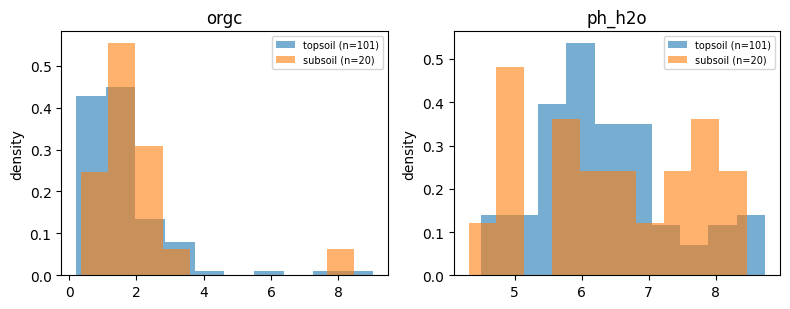

In [21]:
if calibration_table.shape[0] > 0:
    print(calibration_table.groupby("depth_class")[TARGET_COLUMNS].agg(["count", "mean", "std", "min", "max"]).round(2).T)

    print("\nskewness (by depth class, and all depths together):")
    for target_name in TARGET_COLUMNS:
        skewness_parts = []
        for depth_class_name in ["topsoil", "subsoil"]:
            values_for_depth = calibration_table.loc[calibration_table["depth_class"] == depth_class_name, target_name].dropna()
            if len(values_for_depth) >= 3:
                skewness_parts.append(f"{depth_class_name} {stats.skew(values_for_depth):.2f} (n={len(values_for_depth)})")
            else:
                skewness_parts.append(f"{depth_class_name} n/a (n={len(values_for_depth)})")
        all_values = calibration_table[target_name].dropna()
        all_text = f"{stats.skew(all_values):.2f}" if len(all_values) >= 3 else "n/a"
        print(f"  {target_name}: " + " | ".join(skewness_parts) + f" | all depths {all_text}")

    print("\ndoes the subsoil range sit inside the topsoil range?")
    for target_name in TARGET_COLUMNS:
        topsoil_values = calibration_table.loc[calibration_table["depth_class"] == "topsoil", target_name].dropna()
        subsoil_values = calibration_table.loc[calibration_table["depth_class"] == "subsoil", target_name].dropna()
        if len(topsoil_values) > 0 and len(subsoil_values) > 0:
            outside_count = int(((subsoil_values < topsoil_values.min()) | (subsoil_values > topsoil_values.max())).sum())
            print(f"  {target_name}: topsoil {topsoil_values.min():.2f} to {topsoil_values.max():.2f} | "
                  f"subsoil {subsoil_values.min():.2f} to {subsoil_values.max():.2f} | "
                  f"subsoil samples outside the topsoil range: {outside_count} of {len(subsoil_values)}")
        else:
            print(f"  {target_name}: cannot compare (a depth class has no values)")

    print("\nplots with BOTH depths (paired comparison, subsoil minus topsoil):")
    for target_name in TARGET_COLUMNS:
        paired_table = calibration_table.pivot_table(index="plot_code", columns="depth_class", values=target_name, aggfunc="mean")
        if {"topsoil", "subsoil"}.issubset(paired_table.columns):
            paired_table = paired_table.dropna(subset=["topsoil", "subsoil"])
            if len(paired_table) > 0:
                depth_differences = paired_table["subsoil"] - paired_table["topsoil"]
                spread_text = f"{depth_differences.std():.2f}" if len(depth_differences) > 1 else "n/a"
                print(f"  {target_name}: {len(paired_table)} plots | mean difference {depth_differences.mean():.2f} | "
                      f"sd {spread_text} | subsoil lower in {int((depth_differences < 0).sum())} of {len(depth_differences)} plots")
                continue
        print(f"  {target_name}: no plots with both depths")

    figure, axes_array = plt.subplots(1, len(TARGET_COLUMNS), figsize=(4 * len(TARGET_COLUMNS), 3.2))
    axes_array = np.atleast_1d(axes_array)
    for axis, target_name in zip(axes_array, TARGET_COLUMNS):
        for depth_class_name in ["topsoil", "subsoil"]:
            values_for_depth = calibration_table.loc[calibration_table["depth_class"] == depth_class_name, target_name].dropna()
            if len(values_for_depth) > 0:
                axis.hist(values_for_depth, bins=10, alpha=0.6, density=True, label=f"{depth_class_name} (n={len(values_for_depth)})")
        axis.set_title(target_name)
        axis.set_ylabel("density")
        axis.legend(fontsize=7)
    figure.tight_layout()
    plt.show()
else:
    print("No calibration samples to describe.")

The results above indicate that:
- SOC is strongly right-skewed (topsoil 3.14, subsoil 2.95), driven by a few high samples (6 to 9).
- pH is close to symmetric (0.60 and 0.03) and spans 4.3 to 8.7.
- In 18 plots with both depths, subsoil SOC is lower in only 6, and pH shows no consistent shift. The depth effect is weak in this data, and subsoil SOC is not lower than topsoil as is usually the case.
- Subsoil pH has two clusters (about 4.7 to 5 and 7.5 to 8.5), which may reflect different regions.

### 2.5 Coordinates
Coordinates are checked to be numbers  and are inside the expected study area

Samples with wrong coordinates cannot be assigned to a block, so they are left out of the modelling

In [22]:
for coordinate_name in [LONGITUDE_COLUMN, LATITUDE_COLUMN]:
    calibration_table[coordinate_name] = pd.to_numeric(calibration_table[coordinate_name], errors="coerce")

missing_coordinate_mask = calibration_table[[LONGITUDE_COLUMN, LATITUDE_COLUMN]].isna().any(axis=1)
print("Missing or unreadable coordinates", missing_coordinate_mask.sum(), "left out of modelling")

outside_area_mask = (~missing_coordinate_mask) & (
    (calibration_table[LONGITUDE_COLUMN] < EXPECTED_LONGITUDE_RANGE[0])
    | (calibration_table[LONGITUDE_COLUMN] > EXPECTED_LONGITUDE_RANGE[1])
    | (calibration_table[LATITUDE_COLUMN] < EXPECTED_LATITUDE_RANGE[0])
    | (calibration_table[LATITUDE_COLUMN] > EXPECTED_LATITUDE_RANGE[1])
)

print("Coordinates outside the expected study area", outside_area_mask.sum(), "treated as missing (left out of modelling)")
print(calibration_table.loc[outside_area_mask, [LONGITUDE_COLUMN, LATITUDE_COLUMN]].head())
if outside_area_mask.any():
    calibration_table.loc[outside_area_mask, [LONGITUDE_COLUMN, LATITUDE_COLUMN]] = np.nan

Missing or unreadable coordinates 0 left out of modelling
Coordinates outside the expected study area 0 treated as missing (left out of modelling)
Empty DataFrame
Columns: [X, Y]
Index: []


### 2.6 Spectra: integrity checks
Checks all spectra both calibration and spectra-only

In [23]:
def remove_layer_ids(layer_ids_to_remove, calibration_table, calibration_spectra, prediction_metadata, prediction_spectra):
    # Drop the given samples from every set and return the four reduced tables.
    layer_ids_to_remove = pd.Index(layer_ids_to_remove)
    calibration_table = calibration_table.loc[~calibration_table.index.isin(layer_ids_to_remove)]
    calibration_spectra = calibration_spectra.loc[~calibration_spectra.index.isin(layer_ids_to_remove)]
    prediction_metadata = prediction_metadata.loc[~prediction_metadata.index.isin(layer_ids_to_remove)]
    prediction_spectra = prediction_spectra.loc[~prediction_spectra.index.isin(layer_ids_to_remove)]
    return calibration_table, calibration_spectra, prediction_metadata, prediction_spectra


all_spectra = pd.concat([calibration_spectra, prediction_spectra])

# checking for missing values
missing_fraction_per_spectrum = all_spectra.isna().mean(axis=1)
too_many_gaps = missing_fraction_per_spectrum[missing_fraction_per_spectrum > MAXIMUM_MISSING_FRACTION_PER_SPECTRUM]
some_gaps = missing_fraction_per_spectrum[(missing_fraction_per_spectrum > 0)
                                          & (missing_fraction_per_spectrum <= MAXIMUM_MISSING_FRACTION_PER_SPECTRUM)]

print(f"spectra with more than {MAXIMUM_MISSING_FRACTION_PER_SPECTRUM:.0%} missing values",
                 len(too_many_gaps), "spectra and their samples removed")
print("spectra with a few missing values", len(some_gaps), "filled by linear interpolation")


spectra with more than 5% missing values 0 spectra and their samples removed
spectra with a few missing values 0 filled by linear interpolation


In [24]:
# checking for constant spectra values
spread_per_spectrum = all_spectra.std(axis=1)
constant_spectra = spread_per_spectrum[(spread_per_spectrum == 0) | spread_per_spectrum.isna()]
constant_spectra = constant_spectra[~constant_spectra.index.isin(too_many_gaps.index)]
print("Constant flat spectra", len(constant_spectra), "spectra and their samples removed")

layer_ids_to_remove = too_many_gaps.index.union(constant_spectra.index)
calibration_table, calibration_spectra, prediction_metadata, prediction_spectra = remove_layer_ids(
    layer_ids_to_remove, calibration_table, calibration_spectra, prediction_metadata, prediction_spectra
)
calibration_spectra = calibration_spectra.interpolate(axis=1, method="index", limit_direction="both")
prediction_spectra = prediction_spectra.interpolate(axis=1, method="index", limit_direction="both")

Constant flat spectra 0 spectra and their samples removed


In [25]:
# checking spectra value range
all_spectra = pd.concat([calibration_spectra, prediction_spectra])
print("spectra kept => calibration", calibration_spectra.shape[0], "| spectra-only", prediction_spectra.shape[0])
print("absorbance range => min", float(all_spectra.min().min()), "| max", float(all_spectra.max().max()))
negative_share = float((all_spectra < 0).to_numpy().mean())
print(f"share of negative values: {negative_share:.4%}")

print("Negative values in spectra ", int((all_spectra < 0).any(axis=1).sum()))

spectra kept => calibration 121 | spectra-only 669
absorbance range => min 1.041959229 | max 3.266187765
share of negative values: 0.0000%
Negative values in spectra  0


### 2.7 Bridging the CO2 region, trim the noisy edge and thin the wavenumber grid
Three operations are applied identically to every spectrum:
1. **Bridge** the ranges in `WAVENUMBER_RANGES_TO_INTERPOLATE` with a straight line between the values on either side. The axis stays regular, which keeps derivative calculations correct.
2. **Remove** the ranges in `WAVENUMBER_RANGES_TO_REMOVE` which is the the noisy edge.
3. **Keep every `DOWNSAMPLE_STEP`-th point** of what remains.

The plot shows the spread across samples at each wavenumber. 

Very noisy ranges stand out as spikes

wavenumbers before: 1703 | after bridging, trimming and thinning: 827
model range: 601.9 to 3996.0 cm-1


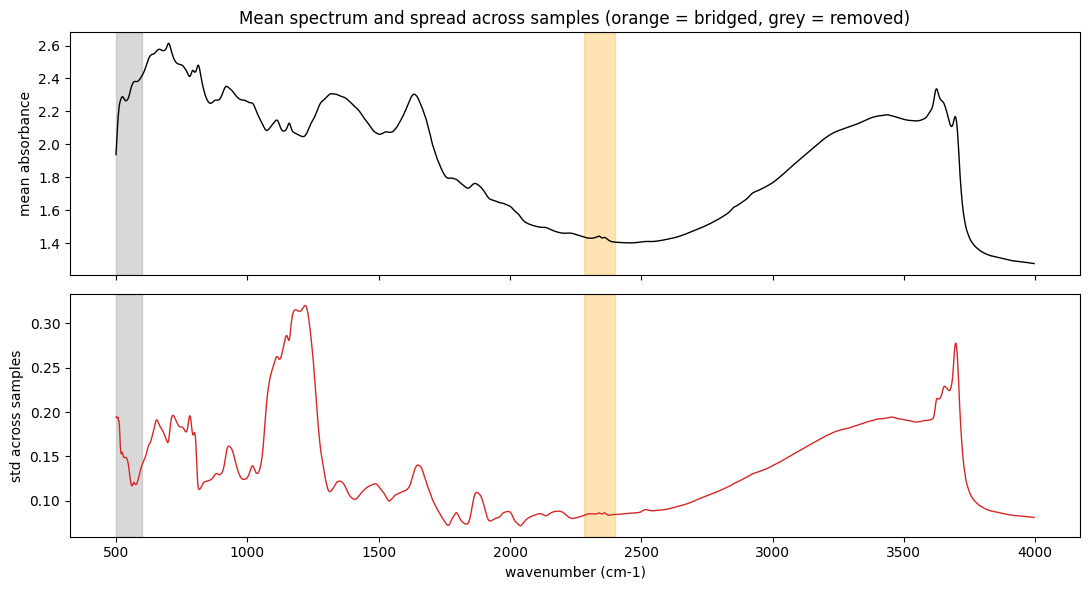

In [26]:
def interpolate_across_ranges(spectra_frame, wavenumber_array, ranges_to_bridge):
    values = spectra_frame.to_numpy(dtype=float).copy()
    for lower_limit, upper_limit in ranges_to_bridge:
        inside_positions = np.flatnonzero((wavenumber_array >= lower_limit) & (wavenumber_array <= upper_limit))
        if inside_positions.size == 0:
            continue
        left_position = inside_positions[0] - 1
        right_position = inside_positions[-1] + 1
        if left_position < 0 or right_position >= wavenumber_array.size:
            print(f"   range {lower_limit}-{upper_limit} touches the edge of the spectrum; use WAVENUMBER_RANGES_TO_REMOVE instead")
            continue
        weights = (wavenumber_array[inside_positions] - wavenumber_array[left_position]) / (
            wavenumber_array[right_position] - wavenumber_array[left_position]
        )
        values[:, inside_positions] = (
            (1 - weights)[None, :] * values[:, [left_position]] + weights[None, :] * values[:, [right_position]]
        )
    return pd.DataFrame(values, index=spectra_frame.index, columns=spectra_frame.columns)


def select_model_positions(wavenumber_array, ranges_to_remove, step):
    keep_mask = np.ones(wavenumber_array.size, dtype=bool)
    for lower_limit, upper_limit in ranges_to_remove:
        keep_mask &= ~((wavenumber_array >= lower_limit) & (wavenumber_array <= upper_limit))
    return np.flatnonzero(keep_mask)[::step]


spread_before = all_spectra.std(axis=0)

calibration_spectra = interpolate_across_ranges(calibration_spectra, wavenumber_values, WAVENUMBER_RANGES_TO_INTERPOLATE)
prediction_spectra = interpolate_across_ranges(prediction_spectra, wavenumber_values, WAVENUMBER_RANGES_TO_INTERPOLATE)

kept_positions = select_model_positions(wavenumber_values, WAVENUMBER_RANGES_TO_REMOVE, DOWNSAMPLE_STEP)
model_wavenumbers = wavenumber_values[kept_positions]
calibration_model_spectra = calibration_spectra.iloc[:, kept_positions]
prediction_model_spectra = prediction_spectra.iloc[:, kept_positions]
all_model_spectra = pd.concat([calibration_model_spectra, prediction_model_spectra])

print("wavenumbers before:", wavenumber_values.size, "| after bridging, trimming and thinning:", model_wavenumbers.size)
print("model range:", model_wavenumbers.min(), "to", model_wavenumbers.max(), "cm-1")

figure, axes_array = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes_array[0].plot(wavenumber_values, all_spectra.mean(axis=0), color="black", linewidth=1)
axes_array[0].set_ylabel("mean absorbance")
axes_array[1].plot(wavenumber_values, spread_before, color="tab:red", linewidth=1)
axes_array[1].set_ylabel("std across samples")
axes_array[1].set_xlabel("wavenumber (cm-1)")
for axis in axes_array:
    for lower_limit, upper_limit in WAVENUMBER_RANGES_TO_INTERPOLATE:
        axis.axvspan(lower_limit, upper_limit, color="orange", alpha=0.3)
    for lower_limit, upper_limit in WAVENUMBER_RANGES_TO_REMOVE:
        axis.axvspan(lower_limit, upper_limit, color="grey", alpha=0.3)
axes_array[0].set_title("Mean spectrum and spread across samples (orange = bridged, grey = removed)")
figure.tight_layout()
plt.show()

1,703 wavenumbers became 827 (601.9 to 3996.0 cm-1) after trimming 499 to 600, bridging 2280 to 2400 and keeping every second point.
    
The trimmed edge is unstable as shown in the sharp jump in the mean and high between-sample spread so trimming is justified.
    
No CO2 spike is visible in 2280 to 2400 so the bridge changes almost nothing here.
    
Between-sample variation is largest at 1000 to 1250 cm-1 (Si–O, mineral composition) and near 3600 to 3700 cm-1 (clay O–H).
    
The spread never falls below about 0.08, which points to baseline and scatter differences between spectra. This is the reason for comparing SNV, MSC and derivative preprocessing.

# Step 3: Spatial blocks for validation

Plots close together tend to have similar soils and spectra. A model tested on a plot whose neighbour was in the training data looks better than it will be on a new area. To avoid this, whole neighbourhoods called **spatial blocks** are held out together.

Blocks are built from one point per plot (topsoil and subsoil together). Coordinates are converted to kilometres and grouped by k-means, and every sample gets its plot's block label. Coordinates are used only to make blocks, never as model inputs.

### 3.1 Project the coordinates and build the blocks
Coordinates are projected to kilometres (UTM zone 37S) and clustered into blocks. The same function is rerun with other random seeds to check that the block layout does not drive the results. Agreement between layouts is measured with the adjusted Rand index (1 = identical).

In [27]:
def project_to_kilometres(longitude_values, latitude_values):
    if PYPROJ_AVAILABLE:
        transformer = Transformer.from_crs("EPSG:4326", "EPSG:32737", always_xy=True)
        easting, northing = transformer.transform(np.asarray(longitude_values), np.asarray(latitude_values))
        return np.column_stack([np.asarray(easting) / 1000.0, np.asarray(northing) / 1000.0])
    mean_latitude_radians = np.deg2rad(np.mean(latitude_values))
    easting = np.asarray(longitude_values) * 111.32 * np.cos(mean_latitude_radians)
    northing = np.asarray(latitude_values) * 110.57
    return np.column_stack([easting, northing])


def build_blocks(plot_centres_table, block_count, seed):
    coordinates_km = project_to_kilometres(plot_centres_table[LONGITUDE_COLUMN], plot_centres_table[LATITUDE_COLUMN])
    clustering = KMeans(n_clusters=block_count, n_init=10, random_state=seed)
    labels = clustering.fit_predict(coordinates_km)
    return pd.Series(labels, index=plot_centres_table.index, name="spatial_block")


if modelling_possible:
    plot_centres = (calibration_table.loc[calibration_table["has_coordinates"]]
                    .groupby("plot_code")[[LONGITUDE_COLUMN, LATITUDE_COLUMN]].mean())
    print("plots to cluster:", plot_centres.shape[0])

    block_labels_by_seed[PRIMARY_BLOCK_SEED] = build_blocks(plot_centres, effective_block_count, PRIMARY_BLOCK_SEED)
    for extra_seed in STABILITY_BLOCK_SEEDS:
        block_labels_by_seed[extra_seed] = build_blocks(plot_centres, effective_block_count, extra_seed)

    # How similar are the layouts from different seeds? 1.0 = identical grouping.
    primary_labels = block_labels_by_seed[PRIMARY_BLOCK_SEED]
    for extra_seed in STABILITY_BLOCK_SEEDS:
        agreement = adjusted_rand_score(primary_labels, block_labels_by_seed[extra_seed])
        print(f"agreement between seed {PRIMARY_BLOCK_SEED} and seed {extra_seed} layouts (adjusted Rand): {agreement:.2f}")

NameError: name 'modelling_possible' is not defined

The layouts from seeds 7, 123 and 2024 agree closely with the main layout (0.89, 0.94 and 0.89). Seed 99 differs more (0.68). The layout is therefore fairly stable, and Step 6.8 tests whether the accuracy depends on it.

### 3.2 Attach the blocks and inspect them
Calibration samples with coordinates form the modelling set. The block summary and map show whether each block has enough plots and whether the property values are spread across the blocks.

In [ ]:
if modelling_possible:
    modelling_table = calibration_table.loc[calibration_table["has_coordinates"]].copy()
    modelling_table["spatial_block"] = modelling_table["plot_code"].map(block_labels_by_seed[PRIMARY_BLOCK_SEED])
    modelling_spectra = calibration_model_spectra.loc[modelling_table.index]

    left_out_count = calibration_table.shape[0] - modelling_table.shape[0]
    if left_out_count > 0:
        print(f"{left_out_count} calibration samples without usable coordinates were left out of modelling (no block can be assigned)")

    block_summary = modelling_table.groupby("spatial_block").agg(
        plots=("plot_code", "nunique"),
        samples=("plot_code", "size"),
        topsoil=("depth_class", lambda values: int((values == "topsoil").sum())),
        **{f"{target_name}_mean": (target_name, "mean") for target_name in TARGET_COLUMNS},
    ).round(2)
    print(block_summary)

    figure, axes_array = plt.subplots(1, 2, figsize=(13, 5))
    plot_level = modelling_table.groupby("plot_code").agg(
        longitude=(LONGITUDE_COLUMN, "mean"), latitude=(LATITUDE_COLUMN, "mean"), block=("spatial_block", "first"))
    scatter = axes_array[0].scatter(plot_level["longitude"], plot_level["latitude"], c=plot_level["block"], cmap="tab10", s=40)
    axes_array[0].set_xlabel("longitude")
    axes_array[0].set_ylabel("latitude")
    axes_array[0].set_title("Calibration plots coloured by spatial block")
    block_summary["samples"].plot(kind="bar", ax=axes_array[1], color="steelblue")
    axes_array[1].set_title("Samples per block")
    axes_array[1].set_xlabel("block")
    figure.tight_layout()
    plt.show()
else:
    print("skipped (modelling not possible)")

The results above indicate that:
- The 121 samples fall into 8 compact geographic blocks of 8 to 16 plots (8 to 19 samples). The plots cover about 34 to 40°E and 4.3°S to 1.2°N.
- Block 2 is the smallest, with 8 plots and 8 samples. Every block has some subsoil samples, but only 1 to 4 each (block 2 has just 1).
- The blocks differ in pH: the means range from 5.55 (block 3) and 5.60 (block 6) to 7.30 (block 2), 7.01 (block 4), 6.81 (block 0) and 6.71 (block 1). Holding out a block therefore tests the model on soils with a different pH from the training data, which makes the validation demanding.
- The mean SOC per block ranges from 1.13 to 2.63, with block 2 the highest.

# Step 4: Spectral preprocessing

Raw spectra contain differences that are not soil chemistry, such as baseline shifts from particle size and packing. Six preprocessing methods are compared (Objective 2):

| Name | Method |
|---|---|
| `raw` | none |
| `snv` | Standard Normal Variate: each spectrum is centred and scaled by its own mean and standard deviation |
| `msc` | Multiplicative Scatter Correction: each spectrum is corrected towards the mean spectrum |
| `sg1` | Savitzky–Golay first derivative |
| `sg2` | Savitzky–Golay second derivative |
| `snv_sg1` | SNV followed by the first derivative |

Each method learns what it needs (for example the MSC reference spectrum) from the training data only, so nothing from a test fold leaks into training.

In [ ]:
COMPONENT_MODULE_NAME = "mir_pipeline_components"
COMPONENT_MODULE_PATH = Path(COMPONENT_MODULE_NAME + ".py")
COMPONENT_SOURCE = r'''# Custom scikit-learn components of the MIR calibration pipeline.
# The notebook writes this file; the Django service must import the SAME file to load the saved models.
import numpy as np
from scipy.signal import savgol_filter
from sklearn.base import BaseEstimator, TransformerMixin, clone


class IdentityTransformer(BaseEstimator, TransformerMixin):
    # Leaves the spectra unchanged (the 'raw' option).
    def fit(self, spectra_matrix, target_values=None):
        self.is_fitted_ = True   # stateless, but scikit-learn needs a fitted marker
        return self

    def transform(self, spectra_matrix):
        return np.asarray(spectra_matrix, dtype=float)


class StandardNormalVariate(BaseEstimator, TransformerMixin):
    # SNV: every spectrum is centred and scaled by its own mean and standard deviation.
    def fit(self, spectra_matrix, target_values=None):
        self.is_fitted_ = True   # stateless, but scikit-learn needs a fitted marker
        return self

    def transform(self, spectra_matrix):
        spectra_matrix = np.asarray(spectra_matrix, dtype=float)
        row_means = spectra_matrix.mean(axis=1, keepdims=True)
        row_standard_deviations = spectra_matrix.std(axis=1, ddof=1, keepdims=True)
        row_standard_deviations[row_standard_deviations == 0] = 1.0
        return (spectra_matrix - row_means) / row_standard_deviations


class MultiplicativeScatterCorrection(BaseEstimator, TransformerMixin):
    # MSC: fit learns the mean (reference) spectrum from the TRAINING spectra only.
    def fit(self, spectra_matrix, target_values=None):
        self.reference_spectrum_ = np.asarray(spectra_matrix, dtype=float).mean(axis=0)
        return self

    def transform(self, spectra_matrix):
        spectra_matrix = np.asarray(spectra_matrix, dtype=float)
        corrected = np.empty_like(spectra_matrix)
        for row_position in range(spectra_matrix.shape[0]):
            slope, intercept = np.polyfit(self.reference_spectrum_, spectra_matrix[row_position], deg=1)
            if abs(slope) < 1e-12:
                slope = 1.0
            corrected[row_position] = (spectra_matrix[row_position] - intercept) / slope
        return corrected


class SavitzkyGolayDerivative(BaseEstimator, TransformerMixin):
    # Smoothing + differentiation along the wavenumber axis (derivative_order 1 or 2).
    def __init__(self, window_length=11, polynomial_order=2, derivative_order=1):
        self.window_length = window_length
        self.polynomial_order = polynomial_order
        self.derivative_order = derivative_order

    def fit(self, spectra_matrix, target_values=None):
        self.is_fitted_ = True   # stateless, but scikit-learn needs a fitted marker
        return self

    def transform(self, spectra_matrix):
        spectra_matrix = np.asarray(spectra_matrix, dtype=float)
        window_length = min(self.window_length, spectra_matrix.shape[1] - (1 - spectra_matrix.shape[1] % 2))
        return savgol_filter(spectra_matrix, window_length=window_length, polyorder=self.polynomial_order,
                             deriv=self.derivative_order, axis=1)


class SpectraAndDepthPreprocessor(BaseEstimator, TransformerMixin):
    # Applies a spectral preprocessing to the spectral columns and (optionally) appends the depth indicator.
    # Expected input: spectral columns first, then ONE depth-indicator column (1 = topsoil, 0 = subsoil).
    def __init__(self, preprocessing=None, spectral_column_count=0, use_depth_flag=False):
        self.preprocessing = preprocessing
        self.spectral_column_count = spectral_column_count
        self.use_depth_flag = use_depth_flag

    def fit(self, feature_matrix, target_values=None):
        feature_matrix = np.asarray(feature_matrix, dtype=float)
        spectral_part = feature_matrix[:, : self.spectral_column_count]
        self.preprocessing_ = clone(self.preprocessing).fit(spectral_part)
        processed_part = self.preprocessing_.transform(spectral_part)
        # The depth column is scaled to the size of a typical processed wavelength.
        self.depth_weight_ = float(np.mean(processed_part.std(axis=0))) if self.use_depth_flag else 0.0
        return self

    def transform(self, feature_matrix):
        feature_matrix = np.asarray(feature_matrix, dtype=float)
        processed_part = self.preprocessing_.transform(feature_matrix[:, : self.spectral_column_count])
        if not self.use_depth_flag:
            return processed_part
        depth_column = feature_matrix[:, [self.spectral_column_count]] * self.depth_weight_
        return np.hstack([processed_part, depth_column])
'''

# The classes live in a real module so that saved models can be loaded by another program,
# such as the Django service, which only needs this one file next to it.
COMPONENT_MODULE_PATH.write_text(COMPONENT_SOURCE)
sys.path.insert(0, str(COMPONENT_MODULE_PATH.resolve().parent))
os.environ["PYTHONPATH"] = str(COMPONENT_MODULE_PATH.resolve().parent) + os.pathsep + os.environ.get("PYTHONPATH", "")   # parallel workers need it too
importlib.invalidate_caches()
if COMPONENT_MODULE_NAME in sys.modules:
    importlib.reload(sys.modules[COMPONENT_MODULE_NAME])
from mir_pipeline_components import (IdentityTransformer, StandardNormalVariate, MultiplicativeScatterCorrection,
                                     SavitzkyGolayDerivative, SpectraAndDepthPreprocessor)
print("component module written to", COMPONENT_MODULE_PATH.resolve())


def build_preprocessing_pipeline(preprocessing_name):
    if preprocessing_name == "raw":
        return Pipeline([("identity", IdentityTransformer())])
    if preprocessing_name == "snv":
        return Pipeline([("snv", StandardNormalVariate())])
    if preprocessing_name == "msc":
        return Pipeline([("msc", MultiplicativeScatterCorrection())])
    if preprocessing_name == "sg1":
        return Pipeline([("sg1", SavitzkyGolayDerivative(SAVITZKY_GOLAY_WINDOW, SAVITZKY_GOLAY_POLYNOMIAL, 1))])
    if preprocessing_name == "sg2":
        return Pipeline([("sg2", SavitzkyGolayDerivative(SAVITZKY_GOLAY_WINDOW, SAVITZKY_GOLAY_POLYNOMIAL, 2))])
    if preprocessing_name == "snv_sg1":
        return Pipeline([("snv", StandardNormalVariate()),
                         ("sg1", SavitzkyGolayDerivative(SAVITZKY_GOLAY_WINDOW, SAVITZKY_GOLAY_POLYNOMIAL, 1))])
    raise ValueError(f"Unknown preprocessing '{preprocessing_name}'")


ALL_PREPROCESSING_NAMES = ["raw", "snv", "msc", "sg1", "sg2", "snv_sg1"]
print("preprocessing methods available:", ALL_PREPROCESSING_NAMES)
print("methods that will be run:", PREPROCESSINGS_TO_RUN)

The helper module `mir_pipeline_components.py` was written next to the notebook. It is needed later by the Django service. All six preprocessing methods will be run.

### 4.1 Self-checks
Each method is tested on inputs with a known answer. All lines must say PASS.

In [ ]:
random_generator = np.random.default_rng(0)
test_spectra = random_generator.normal(2.0, 0.3, size=(6, 120)) + np.linspace(0, 1, 120)

snv_result = StandardNormalVariate().fit_transform(test_spectra)
print("SNV row means ~ 0 :", "PASS" if np.allclose(snv_result.mean(axis=1), 0, atol=1e-9) else "FAIL")
print("SNV row stds  ~ 1 :", "PASS" if np.allclose(snv_result.std(axis=1, ddof=1), 1, atol=1e-9) else "FAIL")

reference_spectrum = test_spectra.mean(axis=0)
stretched_copy = 1.7 * reference_spectrum + 0.4
scatter_corrector = MultiplicativeScatterCorrection().fit(test_spectra)
corrected_copy = scatter_corrector.transform(stretched_copy[None, :])[0]
print("MSC recovers the reference:", "PASS" if np.allclose(corrected_copy, scatter_corrector.reference_spectrum_, atol=1e-8) else "FAIL")

straight_line = np.arange(120, dtype=float)[None, :]
first_derivative = SavitzkyGolayDerivative(11, 2, 1).fit_transform(straight_line)
second_derivative = SavitzkyGolayDerivative(11, 2, 2).fit_transform(straight_line)
print("SG first derivative of a line = 1 :", "PASS" if np.allclose(first_derivative, 1.0, atol=1e-8) else "FAIL")
print("SG second derivative of a line = 0:", "PASS" if np.allclose(second_derivative, 0.0, atol=1e-8) else "FAIL")

All five self-checks pass (SNV mean and standard deviation, MSC recovery of the reference, first and second derivative of a straight line).

### 4.2 What each method does to real spectra
Eight spectra (blue = topsoil, red = subsoil) after each preprocessing.

In [ ]:
preview_spectra = all_model_spectra.iloc[: min(8, all_model_spectra.shape[0])]
preview_depth = pd.concat([calibration_table["depth_class"], prediction_metadata["depth_class"]]).reindex(preview_spectra.index)

figure, axes_array = plt.subplots(2, 3, figsize=(16, 7), sharex=True)
for axis, preprocessing_name in zip(axes_array.ravel(), ALL_PREPROCESSING_NAMES):
    processed_preview = build_preprocessing_pipeline(preprocessing_name).fit_transform(preview_spectra.to_numpy())
    for row_position, layer_id in enumerate(preview_spectra.index):
        line_colour = "tab:blue" if preview_depth.loc[layer_id] == "topsoil" else "tab:red"
        axis.plot(model_wavenumbers, processed_preview[row_position], color=line_colour, linewidth=0.8, alpha=0.8)
    axis.set_title(preprocessing_name)
for axis in axes_array[-1]:
    axis.set_xlabel("wavenumber (cm-1)")
figure.tight_layout()
plt.show()

The results above indicate that:
- In the raw spectra the curves are shifted vertically from each other, and one spectrum sits clearly higher over most of the range. This is the baseline and scatter variation.
- SNV and MSC remove most of the vertical shift, and the curves line up.
- The derivatives remove the broad hump and sharpen the peaks. The steep drop near 3700 cm-1 produces by far the largest feature in all three derivative versions, and the second derivative is noisy below about 1500 cm-1.

# Step 5: Models and tuning grids

Four candidate algorithms are compared.

| Name | Algorithm |
|---|---|
| `pls` | Partial least squares regression, the standard in spectroscopy |
| `ridge` | Ridge regression, a penalised linear model |
| `svr` | Support vector regression (RBF kernel) |
| `random_forest` | Random forest |

Design decisions:
- **Depth class** is a 0/1 input column (1 = topsoil) when both depths have at least `MINIMUM_SAMPLES_PER_DEPTH_CLASS` samples.
- **Hyperparameters** are tuned only inside the training data, by an inner cross-validation.
- **Targets** can be modelled on a log scale (`LOG_TRANSFORM_TARGETS`). Predictions are always returned in the original units.

### 5.1 Building blocks

In [ ]:
def build_feature_matrix(spectra_frame, depth_class_values):
    # Spectral columns + a final 0/1 column (1 = topsoil).
    depth_flag = (np.asarray(depth_class_values) == "topsoil").astype(float)
    return np.hstack([spectra_frame.to_numpy(dtype=float), depth_flag[:, None]])


def build_target_transformer(apply_log, standardise):
    transformer_steps = []
    if apply_log:
        transformer_steps.append(("log", FunctionTransformer(np.log1p, inverse_func=np.expm1, validate=False)))
    if standardise:
        transformer_steps.append(("standardise", StandardScaler()))
    if not transformer_steps:
        transformer_steps.append(("identity", FunctionTransformer(validate=False)))
    return Pipeline(transformer_steps)


def build_model_catalogue(training_sample_count):
    # Each entry: the estimator, its tuning grid, whether to standardise the inputs and the target.
    maximum_components = max(2, min(15, training_sample_count // 4))
    component_options = [count for count in [2, 3, 4, 6, 8, 10, 12, 15] if count <= maximum_components]
    return {
        "pls": {
            "estimator": PLSRegression(scale=False),
            "grid": {"n_components": component_options},
            "scale_features": False, "standardise_target": False,
        },
        "ridge": {
            "estimator": Ridge(),
            "grid": {"alpha": [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]},
            "scale_features": True, "standardise_target": False,
        },
        "elastic_net": {
            "estimator": ElasticNet(max_iter=5000),
            "grid": {"alpha": [0.001, 0.01, 0.1, 1.0], "l1_ratio": [0.2, 0.5, 0.8]},
            "scale_features": True, "standardise_target": True,
        },
        "random_forest": {
            "estimator": RandomForestRegressor(n_estimators=300, n_jobs=1, random_state=0),
            "grid": {"max_features": ["sqrt", 0.33], "min_samples_leaf": [1, 3]},
            "scale_features": False, "standardise_target": False,
        },
        "gradient_boosting": {
            "estimator": GradientBoostingRegressor(n_estimators=300, subsample=0.8, max_features=0.3, random_state=0),
            "grid": {"learning_rate": [0.05, 0.1], "max_depth": [2, 3]},
            "scale_features": False, "standardise_target": False,
        },
        "svr": {
            "estimator": SVR(kernel="rbf", gamma="scale"),
            "grid": {"C": [1.0, 10.0, 100.0], "epsilon": [0.01, 0.1]},
            "scale_features": True, "standardise_target": True,
        },
    }


def build_estimator_and_grid(preprocessing_name, model_name, spectral_column_count, use_depth_flag,
                             apply_log, training_sample_count):
    catalogue_entry = build_model_catalogue(training_sample_count)[model_name]
    model_steps = []
    if catalogue_entry["scale_features"]:
        model_steps.append(("scaler", StandardScaler()))
    model_steps.append(("model", catalogue_entry["estimator"]))
    inner_pipeline = Pipeline([
        ("preprocessing", SpectraAndDepthPreprocessor(build_preprocessing_pipeline(preprocessing_name),
                                                       spectral_column_count, use_depth_flag)),
        *model_steps,
    ])
    full_estimator = TransformedTargetRegressor(
        regressor=inner_pipeline,
        transformer=build_target_transformer(apply_log, catalogue_entry["standardise_target"]),
    )
    tuning_grid = {f"regressor__model__{setting_name}": options
                   for setting_name, options in catalogue_entry["grid"].items()}
    return full_estimator, tuning_grid


print("model catalogue and builders defined")

### 5.2 Tuning grids and smoke test
The table lists what is searched for each model. The smoke test fits every combination on random data to confirm the pipelines run end to end. It says nothing about accuracy.

In [ ]:
grid_rows = []
for model_name, catalogue_entry in build_model_catalogue(160).items():
    grid_rows.append({
        "model": model_name,
        "settings tried": {name: options for name, options in catalogue_entry["grid"].items()},
        "candidate combinations": int(np.prod([len(options) for options in catalogue_entry["grid"].values()])),
    })
print(pd.DataFrame(grid_rows).to_string(index=False))

smoke_generator = np.random.default_rng(1)
fake_spectra = smoke_generator.normal(2.0, 0.2, size=(40, 60)) + np.linspace(0, 1, 60)
fake_depth = np.where(smoke_generator.random(40) > 0.5, "topsoil", "subsoil")
fake_feature_matrix = build_feature_matrix(pd.DataFrame(fake_spectra), fake_depth)
fake_target = fake_spectra[:, 10] * 2 + smoke_generator.normal(0, 0.05, 40)

print("\nsmoke test (preprocessing x algorithm):")
smoke_failures = 0
for preprocessing_name in ALL_PREPROCESSING_NAMES:
    for model_name in ["pls", "ridge", "elastic_net", "random_forest", "gradient_boosting", "svr"]:
        try:
            estimator, grid = build_estimator_and_grid(preprocessing_name, model_name, 60, True, False, 40)
            first_setting = {name: options[0] for name, options in grid.items()}
            estimator.set_params(**first_setting)
            estimator.fit(fake_feature_matrix, fake_target)
            predictions = estimator.predict(fake_feature_matrix)
            assert predictions.shape[0] == 40 and np.isfinite(predictions).all()
        except Exception as error:
            smoke_failures += 1
            print(f"  FAIL {preprocessing_name} + {model_name}: {error}")
print("smoke test finished:", "all combinations PASS" if smoke_failures == 0 else f"{smoke_failures} FAILED")

The smoke test passes for all combinations. The convergence warning comes from elastic net on the random test data and does not affect the real runs. The PLS grid searches 2 to 15 components.

---
# Step 6: Validation

Nested, spatially blocked cross-validation gives an honest estimate of accuracy on areas the model has not seen.
- **Outer loop:** each fold holds out whole spatial blocks. Every sample is predicted once by a model that never saw its block. All accuracy numbers come from these out-of-fold predictions.
- **Inner loop:** hyperparameters are tuned inside each training set, also by block, so the test blocks are never used for tuning.
- **Comparison scheme:** the best models are repeated with folds grouped by plot only, to show how much accuracy is lost on new areas.

| Metric | Meaning |
|---|---|
| R2 | share of variance explained (negative = worse than predicting the mean) |
| RMSE | typical error, in the property's units |
| RPD | standard deviation of the reference values divided by RMSE (below 1.4 poor, 1.4 to 2.0 screening, above 2.0 good) |
| RPIQ | interquartile range divided by RMSE |
| Bias | average error (positive = over-prediction) |
| CCC | agreement with the 1:1 line |

### 6.1 Functions
Definitions only. Finished combinations are cached in `outputs/cv_cache`, so a stopped run can continue.

In [ ]:
CACHE_DIRECTORY = OUTPUT_DIR / "cv_cache"
CACHE_DIRECTORY.mkdir(parents=True, exist_ok=True)
BLOCK_GROUPING_NAME = "spatial_block"
PLOT_GROUPING_NAME = "plot"


def concordance_correlation(observed_values, predicted_values):
    mean_observed = observed_values.mean()
    mean_predicted = predicted_values.mean()
    covariance = np.mean((observed_values - mean_observed) * (predicted_values - mean_predicted))
    denominator = observed_values.var() + predicted_values.var() + (mean_observed - mean_predicted) ** 2
    return float(2 * covariance / denominator) if denominator > 0 else np.nan


def compute_metrics(observed_values, predicted_values):
    observed_values = np.asarray(observed_values, dtype=float)
    predicted_values = np.asarray(predicted_values, dtype=float)
    residuals = predicted_values - observed_values
    rmse = float(np.sqrt(np.mean(residuals ** 2)))
    standard_deviation = float(np.std(observed_values, ddof=1))
    upper_quartile, lower_quartile = np.percentile(observed_values, [75, 25])
    return {
        "r2": float(r2_score(observed_values, predicted_values)),
        "rmse": rmse,
        "rpd": standard_deviation / rmse if rmse > 0 else np.nan,
        "rpiq": float(upper_quartile - lower_quartile) / rmse if rmse > 0 else np.nan,
        "bias": float(np.mean(residuals)),
        "ccc": concordance_correlation(observed_values, predicted_values),
    }


def describe_rpd(rpd_value):
    if not np.isfinite(rpd_value):
        return "n/a"
    if rpd_value < 1.4:
        return "poor"
    if rpd_value < 2.0:
        return "screening"
    return "good"


def prepare_target_dataset(target_name):
    # All modelling samples that have a reference value for this target, as plain arrays.
    usable_mask = modelling_table[target_name].notna().to_numpy()
    rows = modelling_table.loc[usable_mask]
    topsoil_count = int((rows["depth_class"] == "topsoil").sum())
    subsoil_count = int((rows["depth_class"] == "subsoil").sum())
    use_depth_flag = (topsoil_count >= MINIMUM_SAMPLES_PER_DEPTH_CLASS) and (subsoil_count >= MINIMUM_SAMPLES_PER_DEPTH_CLASS)
    return {
        "target_name": target_name,
        "layer_ids": rows.index,
        "feature_matrix": build_feature_matrix(modelling_spectra.loc[rows.index], rows["depth_class"].to_numpy()),
        "target_values": rows[target_name].to_numpy(dtype=float),
        "block_labels": rows["spatial_block"].to_numpy(),
        "plot_labels": rows["plot_code"].to_numpy(),
        "depth_values": rows["depth_class"].to_numpy(),
        "use_depth_flag": use_depth_flag,
        "apply_log": target_name in LOG_TRANSFORM_TARGETS,
        "spectral_column_count": modelling_spectra.shape[1],
    }


def subset_dataset(dataset, row_mask):
    subset = dict(dataset)
    subset["layer_ids"] = dataset["layer_ids"][row_mask]
    for key in ["feature_matrix", "target_values", "block_labels", "plot_labels", "depth_values"]:
        subset[key] = dataset[key][row_mask]
    return subset


def run_nested_cross_validation(dataset, preprocessing_name, model_name, group_labels, use_depth_flag):
    feature_matrix = dataset["feature_matrix"]
    target_values = dataset["target_values"]
    group_count = np.unique(group_labels).size
    outer_fold_count = min(OUTER_FOLDS, group_count)
    if outer_fold_count < 2:
        raise ValueError("Need at least 2 groups for cross-validation.")

    out_of_fold_predictions = np.full(target_values.shape[0], np.nan)
    fold_rows = []
    outer_splitter = GroupKFold(n_splits=outer_fold_count)
    for fold_number, (training_positions, test_positions) in enumerate(
            outer_splitter.split(feature_matrix, target_values, group_labels), start=1):
        estimator, tuning_grid = build_estimator_and_grid(
            preprocessing_name, model_name, dataset["spectral_column_count"], use_depth_flag,
            dataset["apply_log"], training_positions.size)
        inner_fold_count = min(INNER_FOLDS, np.unique(group_labels[training_positions]).size)
        search = GridSearchCV(
            estimator, tuning_grid, cv=GroupKFold(n_splits=inner_fold_count),
            scoring="neg_root_mean_squared_error", n_jobs=-1, refit=True, error_score=np.nan)
        search.fit(feature_matrix[training_positions], target_values[training_positions],
                   groups=group_labels[training_positions])
        fold_predictions = np.ravel(search.predict(feature_matrix[test_positions]))
        out_of_fold_predictions[test_positions] = fold_predictions
        fold_rmse = float(np.sqrt(np.mean((fold_predictions - target_values[test_positions]) ** 2)))
        fold_rows.append({
            "fold": fold_number,
            "test_samples": test_positions.size,
            "rmse": fold_rmse,
            "best_settings": json.dumps({name.split("__")[-1]: value for name, value in search.best_params_.items()},
                                        default=str),
        })
    return out_of_fold_predictions, pd.DataFrame(fold_rows)


def evaluate_combination(dataset, preprocessing_name, model_name, grouping_name, group_labels, use_depth_flag=None):
    if use_depth_flag is None:
        use_depth_flag = dataset["use_depth_flag"]
    data_fingerprint = joblib.hash((dataset["feature_matrix"], dataset["target_values"], group_labels))[:12]
    cache_name = (f"{dataset['target_name']}__{preprocessing_name}__{model_name}__{grouping_name}"
                  f"__depth{int(use_depth_flag)}__log{int(dataset['apply_log'])}__{data_fingerprint}.joblib")
    cache_path = CACHE_DIRECTORY / cache_name
    if USE_RESULT_CACHE and cache_path.exists():
        cached_result = joblib.load(cache_path)
        cached_result["from_cache"] = True
        return cached_result

    started_at = time.time()
    predictions, fold_table = run_nested_cross_validation(dataset, preprocessing_name, model_name, group_labels, use_depth_flag)
    result = {
        "target_name": dataset["target_name"],
        "preprocessing": preprocessing_name,
        "model": model_name,
        "grouping": grouping_name,
        "layer_ids": list(dataset["layer_ids"]),
        "observed": dataset["target_values"],
        "predictions": predictions,
        "fold_table": fold_table,
        "seconds": time.time() - started_at,
        "from_cache": False,
    }
    joblib.dump(result, cache_path)
    return result


def fit_tuned_model(dataset, preprocessing_name, model_name):
    # Tune on ALL samples (inner folds by block) and return the fitted search object.
    estimator, tuning_grid = build_estimator_and_grid(
        preprocessing_name, model_name, dataset["spectral_column_count"], dataset["use_depth_flag"],
        dataset["apply_log"], dataset["target_values"].size)
    fold_count = min(5, np.unique(dataset["block_labels"]).size)
    search = GridSearchCV(estimator, tuning_grid, cv=GroupKFold(n_splits=fold_count),
                          scoring="neg_root_mean_squared_error", n_jobs=-1, refit=True)
    search.fit(dataset["feature_matrix"], dataset["target_values"], groups=dataset["block_labels"])
    return search


cross_validation_store = {}
cross_validation_failures = []
target_datasets = {}
best_combination_by_target = {}
print("validation functions defined")

### 6.2 Run the experiments in two stages
- **Stage A:** every preprocessing is validated with PLS. The best one for each property (lowest out-of-fold RMSE) goes forward.
- **Stage B:** the candidate algorithms are validated on that best preprocessing. The winner for each property is picked from these.

Stage A shows which preprocessing suits PLS, not whether it also suits the other algorithms. Choosing the preprocessing on the same folds adds a small optimistic bias, which belongs in the limitations.

In [ ]:
best_preprocessings_by_target = {}
stage_a_summary_rows = []


def run_and_store(dataset, target_name, preprocessing_name, model_name):
    try:
        result = evaluate_combination(dataset, preprocessing_name, model_name, BLOCK_GROUPING_NAME, dataset["block_labels"])
    except Exception as error:
        cross_validation_failures.append((target_name, preprocessing_name, model_name, str(error)))
        print(f"  FAILED {preprocessing_name:8s} {model_name:18s}: {error}")
        return None
    cross_validation_store[(target_name, preprocessing_name, model_name, BLOCK_GROUPING_NAME)] = result
    metrics = compute_metrics(result["observed"], result["predictions"])
    timing_text = "cached" if result["from_cache"] else f"{result['seconds']:.0f}s"
    print(f"  {preprocessing_name:8s} {model_name:18s} R2={metrics['r2']:6.3f}  RMSE={metrics['rmse']:8.3f}  ({timing_text})")
    return metrics


if modelling_possible:
    for target_name in TARGET_COLUMNS:
        dataset = prepare_target_dataset(target_name)
        if dataset["target_values"].size < 4 * OUTER_FOLDS:
            print(f"[skip] {target_name}: only {dataset['target_values'].size} usable samples (need at least {4 * OUTER_FOLDS})")
            continue
        target_datasets[target_name] = dataset
        print(f"\n=== {target_name}: {dataset['target_values'].size} samples | "
              f"depth class used as input: {dataset['use_depth_flag']} | log scale: {dataset['apply_log']} ===")

        print(f"Stage A: preprocessing screening with {PREPROCESSING_SCREENING_ALGORITHM}")
        screening_rmse = {}
        for preprocessing_name in PREPROCESSINGS_TO_RUN:
            metrics = run_and_store(dataset, target_name, preprocessing_name, PREPROCESSING_SCREENING_ALGORITHM)
            if metrics is not None:
                screening_rmse[preprocessing_name] = metrics["rmse"]
                stage_a_summary_rows.append({"target": target_name, "preprocessing": preprocessing_name, **metrics})
        if not screening_rmse:
            print("  no preprocessing could be evaluated for this property")
            continue
        ranked_preprocessings = sorted(screening_rmse, key=screening_rmse.get)
        best_preprocessings_by_target[target_name] = ranked_preprocessings[:STAGE_B_PREPROCESSING_COUNT]
        print(f"-> best preprocessing for {target_name}: {best_preprocessings_by_target[target_name]}")

        print("Stage B: algorithm comparison")
        for preprocessing_name in best_preprocessings_by_target[target_name]:
            for model_name in ALGORITHMS_TO_RUN:
                if model_name == PREPROCESSING_SCREENING_ALGORITHM:
                    continue   # already validated in Stage A
                run_and_store(dataset, target_name, preprocessing_name, model_name)
    print("\nfinished. failures:", len(cross_validation_failures))
else:
    print("skipped (modelling not possible with the current files)")

All runs finished with no failures. The results above indicate that:
- **SOC:** no combination predicts SOC. With PLS, R2 is between -0.13 and -0.02 and RMSE between 1.41 and 1.48 for all six preprocessings. The algorithms on the best preprocessing (MSC) do no better (ridge 1.44, SVR 1.46, random forest 1.49). MSC was picked as the best only by a negligible margin.
- **pH:** pH is predicted well. With PLS, R2 is 0.56 to 0.68. MSC (RMSE 0.576) and raw (0.582) are best, and the derivatives are worse (SG1 0.624, SNV+SG1 0.665, SG2 0.678).
- In Stage B, ridge is clearly the best for pH (RMSE 0.488, R2 0.77), ahead of PLS (0.576), SVR (0.634) and random forest (0.676). The linear models do better than the non-linear ones with 121 samples.

### 6.3 Results: ranking and best combination per property
The best combination has the lowest out-of-fold RMSE under spatial-block validation. The full table is saved to `outputs/cv_results_spatial_block.csv`.

In [ ]:
def summarise_store(grouping_name):
    summary_rows = []
    for (target_name, preprocessing_name, model_name, grouping), result in cross_validation_store.items():
        if grouping != grouping_name:
            continue
        metrics = compute_metrics(result["observed"], result["predictions"])
        summary_rows.append({
            "target": target_name, "preprocessing": preprocessing_name, "model": model_name,
            "samples": len(result["observed"]),
            **metrics,
            "rpd_class": describe_rpd(metrics["rpd"]),
            "mean_fold_rmse": result["fold_table"]["rmse"].mean(),
            "sd_fold_rmse": result["fold_table"]["rmse"].std(),
        })
    return pd.DataFrame(summary_rows)


results_table = pd.DataFrame()
if modelling_possible and len(cross_validation_store) > 0:
    results_table = summarise_store(BLOCK_GROUPING_NAME)
    results_table.to_csv(OUTPUT_DIR / "cv_results_spatial_block.csv", index=False)

    for target_name in results_table["target"].unique():
        target_results = results_table[results_table["target"] == target_name].sort_values("rmse")
        best_row = target_results.iloc[0]
        best_combination_by_target[target_name] = (best_row["preprocessing"], best_row["model"])
        print(f"\n=== {target_name}: top 5 of {len(target_results)} combinations (lowest RMSE first) ===")
        print(target_results.head(5)[["preprocessing", "model", "r2", "rmse", "rpd", "rpiq", "bias", "ccc", "rpd_class"]].round(3).to_string(index=False))

    print("\n=== best combination per property ===")
    best_overview = pd.DataFrame([
        results_table[(results_table["target"] == name) & (results_table["preprocessing"] == choice[0])
                      & (results_table["model"] == choice[1])].iloc[0]
        for name, choice in best_combination_by_target.items()
    ])
    print(best_overview[["target", "preprocessing", "model", "samples", "r2", "rmse", "rpd", "rpiq", "bias", "ccc", "rpd_class"]].round(3).to_string(index=False))
else:
    print("skipped (no validation results yet)")

The results above indicate that:
- **SOC (MSC + PLS):** R2 -0.02, RMSE 1.405, RPD 0.99, RPIQ 0.69 and CCC 0.04. This is rated poor. The model predicts about the average SOC for every sample (bias 0.003).
- **pH (MSC + ridge):** R2 0.77, RMSE 0.488, RPD 2.10, RPIQ 2.42, CCC 0.87 and bias -0.05. This is rated good (RPD above 2.0). The best PLS model reaches RPD 1.78, which is screening level.

### 6.4 Paired comparison across folds
The best combination is compared with each other combination on the same folds, using a Wilcoxon signed-rank test. A positive `mean_rmse_difference` means the other one is worse. A p-value below about 0.05 means a reliable difference. With only 8 folds the test has little power.

In [ ]:
def paired_comparison_with_best(target_name, best_choice):
    best_key = (target_name, best_choice[0], best_choice[1], BLOCK_GROUPING_NAME)
    best_fold_rmse = cross_validation_store[best_key]["fold_table"]["rmse"].to_numpy()
    comparison_rows = []
    for (other_target, other_preprocessing, other_model, grouping), result in cross_validation_store.items():
        if other_target != target_name or grouping != BLOCK_GROUPING_NAME:
            continue
        if (other_preprocessing, other_model) == tuple(best_choice):
            continue
        other_fold_rmse = result["fold_table"]["rmse"].to_numpy()
        if other_fold_rmse.size != best_fold_rmse.size:
            continue
        differences = other_fold_rmse - best_fold_rmse
        try:
            p_value = float(stats.wilcoxon(other_fold_rmse, best_fold_rmse).pvalue)
        except ValueError:
            p_value = np.nan
        comparison_rows.append({
            "preprocessing": other_preprocessing, "model": other_model,
            "mean_rmse_difference": float(differences.mean()),
            "folds_where_best_wins": int((differences > 0).sum()),
            "folds": int(differences.size),
            "p_value": p_value,
        })
    return pd.DataFrame(comparison_rows).sort_values("mean_rmse_difference")


if modelling_possible and len(best_combination_by_target) > 0:
    for target_name, best_choice in best_combination_by_target.items():
        comparison_table = paired_comparison_with_best(target_name, best_choice)
        print(f"\n=== {target_name}: best = {best_choice[0]} + {best_choice[1]}; the 6 closest competitors ===")
        print(comparison_table.head(6).round(4).to_string(index=False))
else:
    print("skipped")

The results above indicate that:
- **SOC:** the differences between recipes are tiny (0.004 to 0.064 RMSE units). Some are statistically significant (for example MSC + PLS against SNV + PLS, p 0.039, a difference of 0.004), but a difference this small has no practical meaning. None of the recipes predicts SOC, so there is no real winner.
- **pH:** ridge on MSC beats every competitor, by 0.091 RMSE (raw + PLS) up to 0.158 (SNV+SG1 + PLS). It wins in 6 to 8 of the 8 folds, with p-values from 0.008 to 0.039. The advantage is reliable.

### 6.5 Observed against predicted
Out-of-fold predictions of the best combination. Points on the dashed line are perfect.

In [ ]:
if modelling_possible and len(best_combination_by_target) > 0:
    figure, axes_array = plt.subplots(1, len(best_combination_by_target), figsize=(4.6 * len(best_combination_by_target), 4.4))
    axes_array = np.atleast_1d(axes_array)
    for axis, (target_name, best_choice) in zip(axes_array, best_combination_by_target.items()):
        result = cross_validation_store[(target_name, best_choice[0], best_choice[1], BLOCK_GROUPING_NAME)]
        depth_for_points = target_datasets[target_name]["depth_values"]
        for depth_class_name, colour in [("topsoil", "tab:blue"), ("subsoil", "tab:red")]:
            selected = depth_for_points == depth_class_name
            axis.scatter(result["observed"][selected], result["predictions"][selected], s=18, alpha=0.7,
                         color=colour, label=depth_class_name)
        lower_bound = min(result["observed"].min(), np.nanmin(result["predictions"]))
        upper_bound = max(result["observed"].max(), np.nanmax(result["predictions"]))
        axis.plot([lower_bound, upper_bound], [lower_bound, upper_bound], "k--", linewidth=0.8)
        metrics = compute_metrics(result["observed"], result["predictions"])
        axis.set_title(f"{target_name}: {best_choice[0]} + {best_choice[1]}\nR2={metrics['r2']:.2f}  RMSE={metrics['rmse']:.2f}", fontsize=9)
        axis.set_xlabel("observed")
        axis.set_ylabel("predicted (out-of-fold)")
        axis.legend(fontsize=7)
    figure.tight_layout()
    plt.show()
else:
    print("skipped")

The results above indicate that:
- **SOC:** predictions sit in a flat band between about 0.5 and 2.5 whatever the observed value (0.2 to 9). The few very high samples (about 6, 7.6, 8.5 and 9) are all predicted near 1.5 to 2. The model is not using the spectra to predict SOC.
- **pH:** points follow the 1:1 line, with a scatter of roughly half a pH unit or more. Some of the most alkaline topsoil samples (observed about 8.5) are predicted too low (about 7), and one is predicted too high (9.4).

### 6.5b Accuracy by depth class
The same out-of-fold predictions split by depth. The best combination also gets 95% bootstrap intervals. Results are saved to `outputs/cv_results_by_depth.csv`.

In [ ]:
def bootstrap_metric_interval(observed_values, predicted_values, metric_name, repetitions=1000):
    generator = np.random.default_rng(0)
    sample_count = observed_values.size
    metric_values = []
    for repetition_number in range(repetitions):
        chosen_positions = generator.integers(0, sample_count, sample_count)
        if np.unique(observed_values[chosen_positions]).size < 2:
            continue
        metric_values.append(compute_metrics(observed_values[chosen_positions], predicted_values[chosen_positions])[metric_name])
    if len(metric_values) == 0:
        return np.nan, np.nan
    lower_value, upper_value = np.percentile(metric_values, [2.5, 97.5])
    return float(lower_value), float(upper_value)


depth_metrics_table = pd.DataFrame()
if modelling_possible and len(best_combination_by_target) > 0:
    depth_rows = []
    for (target_name, preprocessing_name, model_name, grouping_name), result in cross_validation_store.items():
        if grouping_name != BLOCK_GROUPING_NAME:
            continue
        depth_values = target_datasets[target_name]["depth_values"]
        for depth_class_name in ["topsoil", "subsoil"]:
            selected = depth_values == depth_class_name
            if selected.sum() < 5:
                continue
            depth_metrics = compute_metrics(result["observed"][selected], result["predictions"][selected])
            depth_rows.append({"target": target_name, "preprocessing": preprocessing_name, "model": model_name,
                               "depth": depth_class_name, "samples": int(selected.sum()), **depth_metrics})
    depth_metrics_table = pd.DataFrame(depth_rows)
    depth_metrics_table.to_csv(OUTPUT_DIR / "cv_results_by_depth.csv", index=False)

    for target_name in best_combination_by_target:
        target_depth_table = depth_metrics_table[depth_metrics_table["target"] == target_name]
        if target_depth_table.empty:
            continue
        print(f"\n=== {target_name}: out-of-fold RMSE by depth class, every combination that was run ===")
        print(target_depth_table.pivot_table(index=["preprocessing", "model"], columns="depth", values="rmse").round(3).to_string())

    best_rows = []
    for target_name, best_choice in best_combination_by_target.items():
        result = cross_validation_store[(target_name, best_choice[0], best_choice[1], BLOCK_GROUPING_NAME)]
        depth_values = target_datasets[target_name]["depth_values"]
        for depth_label in ["all depths", "topsoil", "subsoil"]:
            selected = np.ones(depth_values.size, dtype=bool) if depth_label == "all depths" else depth_values == depth_label
            if selected.sum() < 5:
                continue
            observed_values = result["observed"][selected]
            predicted_values = result["predictions"][selected]
            metrics = compute_metrics(observed_values, predicted_values)
            rmse_low, rmse_high = bootstrap_metric_interval(observed_values, predicted_values, "rmse")
            r2_low, r2_high = bootstrap_metric_interval(observed_values, predicted_values, "r2")
            best_rows.append({
                "target": target_name, "combination": f"{best_choice[0]} + {best_choice[1]}", "depth": depth_label,
                "samples": int(selected.sum()), "mean_observed": round(float(observed_values.mean()), 2),
                "rmse (95% interval)": f"{metrics['rmse']:.3f} ({rmse_low:.3f} to {rmse_high:.3f})",
                "rmse_percent_of_mean": round(100 * metrics["rmse"] / observed_values.mean(), 1),
                "r2 (95% interval)": f"{metrics['r2']:.2f} ({r2_low:.2f} to {r2_high:.2f})",
                "rpd": round(metrics["rpd"], 2), "bias": round(metrics["bias"], 3),
            })
    print("\n=== best combination per property, by depth class ===")
    print(pd.DataFrame(best_rows).to_string(index=False))
else:
    print("skipped")

The results above indicate that:
- **SOC:** R2 is about 0 at both depths (topsoil -0.03, subsoil -0.04), and the RMSE interval is wide (0.91 to 1.85 for all depths), because a few extreme values drive the error.
- **pH:** topsoil R2 is 0.72 (RMSE 0.506, RPD 1.90) and subsoil R2 is 0.91 (RMSE 0.383, RPD 3.47). Subsoil looks better, but it rests on 20 samples and has a wider pH spread (standard deviation 1.33 against 0.96), which raises R2 and RPD. The RMSE intervals overlap (topsoil 0.43 to 0.59, subsoil 0.30 to 0.46), so the absolute errors are not clearly different.
- Ridge on MSC is the best recipe at both depths.

### 6.6 Block validation against plot-only validation
The best combination repeated with folds grouped by plot only. The difference in RMSE is the cost of predicting genuinely new areas.

In [ ]:
if modelling_possible and len(best_combination_by_target) > 0:
    comparison_rows = []
    for target_name, best_choice in best_combination_by_target.items():
        dataset = target_datasets[target_name]
        plot_result = evaluate_combination(dataset, best_choice[0], best_choice[1], PLOT_GROUPING_NAME, dataset["plot_labels"])
        cross_validation_store[(target_name, best_choice[0], best_choice[1], PLOT_GROUPING_NAME)] = plot_result
        plot_metrics = compute_metrics(plot_result["observed"], plot_result["predictions"])
        block_metrics = compute_metrics(
            cross_validation_store[(target_name, best_choice[0], best_choice[1], BLOCK_GROUPING_NAME)]["observed"],
            cross_validation_store[(target_name, best_choice[0], best_choice[1], BLOCK_GROUPING_NAME)]["predictions"])
        comparison_rows.append({
            "target": target_name, "combination": f"{best_choice[0]} + {best_choice[1]}",
            "r2_block": block_metrics["r2"], "r2_plot_only": plot_metrics["r2"],
            "rmse_block": block_metrics["rmse"], "rmse_plot_only": plot_metrics["rmse"],
            "rmse_increase_on_new_areas": block_metrics["rmse"] - plot_metrics["rmse"],
        })
    print(pd.DataFrame(comparison_rows).round(3).to_string(index=False))
else:
    print("skipped")

The results above indicate that:
- **SOC:** the result is the same under both schemes (R2 -0.023 and -0.028). The lack of skill is not caused by the spatial separation.
- **pH:** RMSE rises only from 0.452 to 0.488 on new areas (R2 0.804 to 0.772). The cost of predicting new areas is small, so the model relies on the spectra and not on neighbouring plots.

### 6.7 Comparing models by depths
Separate topsoil-only and subsoil-only models are compared with the combined model on the same samples.

In [ ]:
if modelling_possible and RUN_SEPARATE_DEPTH_MODELS and len(best_combination_by_target) > 0:
    depth_comparison_rows = []
    for target_name, best_choice in best_combination_by_target.items():
        dataset = target_datasets[target_name]
        combined_result = cross_validation_store[(target_name, best_choice[0], best_choice[1], BLOCK_GROUPING_NAME)]
        for depth_class_name in ["topsoil", "subsoil"]:
            row_mask = dataset["depth_values"] == depth_class_name
            if row_mask.sum() < MINIMUM_SAMPLES_PER_DEPTH_CLASS * 2:
                print(f"[skip] {target_name} {depth_class_name}: only {int(row_mask.sum())} samples")
                continue
            depth_dataset = subset_dataset(dataset, row_mask)
            if np.unique(depth_dataset["block_labels"]).size < 3:
                print(f"[skip] {target_name} {depth_class_name}: fewer than 3 blocks")
                continue
            separate_result = evaluate_combination(
                depth_dataset, best_choice[0], best_choice[1], f"{BLOCK_GROUPING_NAME}_{depth_class_name}_only",
                depth_dataset["block_labels"], use_depth_flag=False)
            separate_metrics = compute_metrics(separate_result["observed"], separate_result["predictions"])
            combined_metrics = compute_metrics(combined_result["observed"][row_mask], combined_result["predictions"][row_mask])
            depth_comparison_rows.append({
                "target": target_name, "depth": depth_class_name, "samples": int(row_mask.sum()),
                "rmse_combined_model": combined_metrics["rmse"], "rmse_separate_model": separate_metrics["rmse"],
                "r2_combined_model": combined_metrics["r2"], "r2_separate_model": separate_metrics["r2"],
            })
    if depth_comparison_rows:
        print(pd.DataFrame(depth_comparison_rows).round(3).to_string(index=False))
    else:
        print("no depth class had enough samples for a separate model")
else:
    print("skipped")

The results above indicate that:
- **pH:** the combined model is better than the separate models at both depths (topsoil RMSE 0.506 against 0.594, subsoil 0.383 against 0.739). A subsoil-only model with 20 samples is unstable.
- **SOC:** neither version predicts SOC, and the subsoil-only model is worse (R2 -0.30 against -0.04).
- One model for both depths, with depth class as an input, is the better choice.

### 6.8 Combination by block layout
The best combination is revalidated with the other block layouts. The spread of RMSE is the uncertainty on the accuracy figure.

In [ ]:
if modelling_possible and len(best_combination_by_target) > 0 and len(STABILITY_BLOCK_SEEDS) > 0:
    stability_rows = []
    for target_name, best_choice in best_combination_by_target.items():
        dataset = target_datasets[target_name]
        rmse_by_seed = {PRIMARY_BLOCK_SEED: compute_metrics(
            cross_validation_store[(target_name, best_choice[0], best_choice[1], BLOCK_GROUPING_NAME)]["observed"],
            cross_validation_store[(target_name, best_choice[0], best_choice[1], BLOCK_GROUPING_NAME)]["predictions"])["rmse"]}
        for extra_seed in STABILITY_BLOCK_SEEDS:
            seed_blocks = pd.Series(dataset["plot_labels"]).map(block_labels_by_seed[extra_seed]).to_numpy()
            seed_result = evaluate_combination(dataset, best_choice[0], best_choice[1], f"{BLOCK_GROUPING_NAME}_seed{extra_seed}", seed_blocks)
            rmse_by_seed[extra_seed] = compute_metrics(seed_result["observed"], seed_result["predictions"])["rmse"]
        rmse_values = np.array(list(rmse_by_seed.values()))
        stability_rows.append({
            "target": target_name, "combination": f"{best_choice[0]} + {best_choice[1]}",
            "rmse_primary_layout": rmse_by_seed[PRIMARY_BLOCK_SEED],
            "rmse_min": rmse_values.min(), "rmse_max": rmse_values.max(), "rmse_mean": rmse_values.mean(),
            "rmse_sd": rmse_values.std(ddof=1) if rmse_values.size > 1 else np.nan,
        })
    print(pd.DataFrame(stability_rows).round(3).to_string(index=False))
else:
    print("skipped")

The results above indicate that:
- **SOC:** RMSE ranges from 1.405 to 1.499 across the layouts (mean 1.434, sd 0.037). The lack of skill holds for every layout.
- **pH:** RMSE ranges from 0.474 to 0.544 (mean 0.493, sd 0.029). The accuracy is stable, and can be reported as about 0.49 with a variation of about 0.03 across layouts.

### Summary of Step 6
- **pH** is predicted well by ridge on MSC spectra: R2 0.77, RMSE about 0.49 and RPD 2.1 on unseen areas. The result is stable across block layouts, and it is only slightly worse on new areas than within known areas. One model for both depths works better than separate models.
- **SOC** is not predicted by any combination (R2 about 0, RPD about 1). The same holds at both depths, under both validation schemes and across layouts.
- **Preprocessing** has a modest effect on pH (MSC and raw best, derivatives worse) and no meaningful effect on SOC.
- **Algorithms:** the linear models (ridge, PLS) beat the non-linear ones (SVR, random forest) for pH with 121 samples.
- **To investigate for SOC:** the strong right skew and the few very high values (about 6 to 9), which dominate the error. Check those samples, test the log scale (`LOG_TRANSFORM_TARGETS`), and look at results with and without them.

# Step 7: Interpretation

A model should predict for the right reasons. Two views:
1. **PLS VIP and coefficients** across the spectrum. VIP above 1 marks wavenumbers that contribute more than average.
2. **Band permutation importance** for the overall best model. In held-out blocks, one 100 cm-1 band of the preprocessed spectrum is scrambled between samples, and the rise in error is measured.

Shaded areas are approximate known absorption regions. Band positions shift with mineralogy and preprocessing, so check against the literature before quoting an assignment.

### 7.1 Functions

In [ ]:
KNOWN_BAND_RANGES = {
    "clay-mineral O-H (kaolinite, smectite)": (3600.0, 3700.0),
    "aliphatic C-H stretch (organic matter)": (2800.0, 3000.0),
    "carbonate (approx.)": (2490.0, 2540.0),
    "C=O / carboxylate (organic matter)": (1600.0, 1750.0),
    "carbonate (approx.)  ": (1400.0, 1450.0),
    "Si-O stretch (quartz, silicates, clays)": (1000.0, 1200.0),
    "Al-OH (clay minerals)": (900.0, 940.0),
    "quartz doublet": (770.0, 810.0),
}


def describe_band(band_start, band_end):
    names = [name.strip() for name, (low, high) in KNOWN_BAND_RANGES.items() if band_start <= high and band_end >= low]
    return "; ".join(sorted(set(names))) if names else "-"


def compute_pls_vip(fitted_search, feature_matrix):
    # VIP scores for a fitted PLS model inside a tuned pipeline.
    fitted_pipeline = fitted_search.best_estimator_.regressor_
    pls_model = fitted_pipeline.named_steps["model"]
    processed_matrix = fitted_pipeline.named_steps["preprocessing"].transform(feature_matrix)
    scores = pls_model.transform(processed_matrix)
    weights = pls_model.x_weights_
    y_loadings = np.ravel(pls_model.y_loadings_)[: weights.shape[1]]
    explained = np.sum(scores ** 2, axis=0) * (y_loadings ** 2)
    normalised_weights = weights / np.linalg.norm(weights, axis=0, keepdims=True)
    variable_count = weights.shape[0]
    vip_scores = np.sqrt(variable_count * (normalised_weights ** 2 @ explained) / explained.sum())
    coefficients = np.ravel(pls_model.coef_)
    return vip_scores, coefficients


def band_permutation_importance(dataset, preprocessing_name, model_name, tuned_settings, band_edges, repeat_count=3):
    feature_matrix = dataset["feature_matrix"]
    target_values = dataset["target_values"]
    group_labels = dataset["block_labels"]
    spectral_count = dataset["spectral_column_count"]
    random_generator = np.random.default_rng(0)
    band_positions = [np.flatnonzero((model_wavenumbers >= band_edges[position]) & (model_wavenumbers < band_edges[position + 1]))
                      for position in range(len(band_edges) - 1)]
    importance_sums = np.zeros(len(band_positions))
    fold_count = min(OUTER_FOLDS, np.unique(group_labels).size)

    for training_positions, test_positions in GroupKFold(n_splits=fold_count).split(feature_matrix, target_values, group_labels):
        estimator, unused_grid = build_estimator_and_grid(
            preprocessing_name, model_name, spectral_count, dataset["use_depth_flag"], dataset["apply_log"], training_positions.size)
        estimator.set_params(**tuned_settings)
        estimator.fit(feature_matrix[training_positions], target_values[training_positions])
        test_target = target_values[test_positions]
        # Scramble AFTER preprocessing: scrambling raw spectra would create artificial jumps at the band edges
        # that derivatives and SNV would turn into huge errors unrelated to the chemistry.
        fitted_pipeline = estimator.regressor_
        processed_test = fitted_pipeline[:-1].transform(feature_matrix[test_positions])
        final_model = fitted_pipeline[-1]

        def predict_from_processed(processed_matrix):
            scaled_predictions = np.ravel(final_model.predict(processed_matrix)).reshape(-1, 1)
            return np.ravel(estimator.transformer_.inverse_transform(scaled_predictions))

        baseline_error = np.sqrt(np.mean((predict_from_processed(processed_test) - test_target) ** 2))
        for band_number, positions in enumerate(band_positions):
            if positions.size == 0:
                continue
            error_increases = []
            for repeat_number in range(repeat_count):
                scrambled_matrix = processed_test.copy()
                scrambled_rows = random_generator.permutation(processed_test.shape[0])
                scrambled_matrix[:, positions] = processed_test[scrambled_rows][:, positions]
                scrambled_error = np.sqrt(np.mean((predict_from_processed(scrambled_matrix) - test_target) ** 2))
                error_increases.append(scrambled_error - baseline_error)
            importance_sums[band_number] += np.mean(error_increases)
    return importance_sums / fold_count


print("interpretation functions defined")

### 7.2 PLS variable importance and coefficients
Best PLS model for each property. Top: VIP (dashed line at 1). Bottom: regression coefficients.

In [ ]:
if modelling_possible and len(results_table) > 0 and "pls" in results_table["model"].values:
    for target_name in best_combination_by_target:
        pls_results = results_table[(results_table["target"] == target_name) & (results_table["model"] == "pls")].sort_values("rmse")
        if pls_results.empty:
            continue
        pls_preprocessing = pls_results.iloc[0]["preprocessing"]
        dataset = target_datasets[target_name]
        tuned_search = fit_tuned_model(dataset, pls_preprocessing, "pls")
        vip_scores, coefficients = compute_pls_vip(tuned_search, dataset["feature_matrix"])
        spectral_count = dataset["spectral_column_count"]

        figure, axes_array = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
        axes_array[0].plot(model_wavenumbers, vip_scores[:spectral_count], color="tab:blue", linewidth=1)
        axes_array[0].axhline(1.0, color="black", linestyle="--", linewidth=0.8)
        axes_array[0].set_ylabel("VIP")
        axes_array[1].plot(model_wavenumbers, coefficients[:spectral_count], color="tab:green", linewidth=1)
        axes_array[1].axhline(0.0, color="black", linewidth=0.5)
        axes_array[1].set_ylabel("coefficient")
        axes_array[1].set_xlabel("wavenumber (cm-1)")
        for axis in axes_array:
            for (low, high) in KNOWN_BAND_RANGES.values():
                axis.axvspan(low, high, color="orange", alpha=0.15)
        axes_array[0].set_title(f"{target_name}: PLS ({pls_preprocessing}), components = "
                                f"{tuned_search.best_params_['regressor__model__n_components']}")
        figure.tight_layout()
        plt.show()

        top_positions = np.argsort(vip_scores[:spectral_count])[::-1][:8]
        print(f"{target_name}: wavenumbers with the highest VIP:",
              ", ".join(f"{model_wavenumbers[position]:.0f}" for position in sorted(top_positions)))
        if dataset["use_depth_flag"]:
            print(f"   VIP of the depth-class column: {vip_scores[-1]:.2f}")
else:
    print("skipped (needs validation results that include the PLS model)")

The results above indicate that:
- **SOC:** the PLS model uses only 2 components. The highest VIP values are at 1177 to 1190 cm-1 (Si–O region) and 1346 to 1358 cm-1. The organic C–H region (2800 to 3000) stays below VIP 1. Because the model has no predictive skill, these peaks are not evidence of SOC chemistry. The depth class has VIP 0.37.
- **pH:** the PLS model uses 15 components, the top of the searched range (2 to 15). The strongest VIP (about 3.8) is at 3680 to 3708 cm-1 in the clay-mineral O–H region, with raised VIP at 1000 to 1200 (Si–O), 1400 to 1450 (carbonate) and 1600 to 1750 cm-1 (C=O). The coefficients are strongly negative near 1700 and 2500 cm-1. The depth class has VIP 0.82. The 3700 peak sits on the steep edge of the spectrum, so it should be read with care.
- For pH the important regions match chemistry that is linked to soil acidity (clay minerals, carbonates and organic matter).

### 7.3 Band permutation importance for the overall best model
Bars show the rise in RMSE when a 100 cm-1 band is scrambled. Large bars mark bands the model relies on.

In [ ]:
if modelling_possible and len(best_combination_by_target) > 0:
    band_edges = np.arange(np.floor(model_wavenumbers.min() / 100) * 100, model_wavenumbers.max() + 100, 100)
    band_labels = [f"{int(band_edges[position])}-{int(band_edges[position + 1])}" for position in range(len(band_edges) - 1)]
    importance_by_target = {}
    for target_name, best_choice in best_combination_by_target.items():
        dataset = target_datasets[target_name]
        tuned_search = fit_tuned_model(dataset, best_choice[0], best_choice[1])
        tuned_settings = tuned_search.best_params_
        importance_by_target[target_name] = band_permutation_importance(dataset, best_choice[0], best_choice[1], tuned_settings, band_edges)

        importance_table = pd.DataFrame({
            "band_cm-1": band_labels,
            "error_increase": importance_by_target[target_name],
            "known_region": [describe_band(band_edges[position], band_edges[position + 1]) for position in range(len(band_labels))],
        }).sort_values("error_increase", ascending=False)
        print(f"\n=== {target_name}: {best_choice[0]} + {best_choice[1]} | top 5 bands ===")
        print(importance_table.head(5).round(4).to_string(index=False))

    figure, axes_array = plt.subplots(len(importance_by_target), 1, figsize=(12, 2.6 * len(importance_by_target)), sharex=True)
    axes_array = np.atleast_1d(axes_array)
    for axis, (target_name, importance_values) in zip(axes_array, importance_by_target.items()):
        axis.bar(band_edges[:-1] + 50, importance_values, width=90, color="steelblue")
        axis.set_ylabel(target_name)
    axes_array[-1].set_xlabel("wavenumber band (cm-1)")
    axes_array[0].set_title("Increase in RMSE when a 100 cm-1 band is scrambled (held-out blocks)")
    figure.tight_layout()
    plt.show()
else:
    print("skipped")

The results above indicate that:
- **SOC:** scrambling any band changes the error by almost nothing (between -0.006 and +0.001). The model does not use any part of the spectrum, which agrees with the lack of skill.
- **pH:** scrambling the most important bands roughly doubles the error (RMSE 0.49). The top bands are 1700 to 1800 (+0.51, C=O), 1300 to 1400 (+0.42), 1500 to 1600 (+0.41), 1400 to 1500 (+0.37) and 2400 to 2500 cm-1 (+0.33). The importance is spread over many bands.
- Several of these bands match known organic and carbonate regions. The 2000 to 2300 region, which has no clear soil assignment, also matters, so part of the pH model may use broad baseline shape.
- The 2400 to 2500 band starts where the bridged CO2 region ends, so it should be checked that it is not an artefact.
- Ridge (permutation) and PLS (VIP) emphasise different parts of the spectrum, for example the 3700 peak is large in the PLS VIP but not in the ridge permutation result. Correlated bands share information, so models can use different ones.

# Step 8: Final models

The best combination for each property is refitted on all calibration samples, with the hyperparameters tuned again. Saved in `outputs/final_models/`:
- `final_model_<property>.joblib` and `.json`: the fitted pipeline with its metadata
- `domain_model.joblib`: the spectral domain of the calibration set;
- `mir_pipeline_components.py`: the module that defines the custom preprocessing classes. Any program that loads the models, such as the Django service, needs this file.

### 8.1 Spectral domain model and prediction intervals
- **Domain model:** the distance of a spectrum from the calibration set in PCA space. The threshold is the `DOMAIN_DISTANCE_PERCENTILE` of the calibration samples' own distances.
- **Prediction interval:** the `PREDICTION_INTERVAL_COVERAGE` quantile of the absolute out-of-fold errors, computed separately for topsoil and subsoil (pooled if a depth has fewer than `MINIMUM_SAMPLES_PER_DEPTH_CLASS` samples). It holds for samples inside the domain.

In [ ]:
def fit_domain_model(spectra_frame, component_count, percentile):
    snv_spectra = StandardNormalVariate().fit_transform(spectra_frame.to_numpy(dtype=float))
    usable_components = min(component_count, spectra_frame.shape[0] - 2)
    principal_components = PCA(n_components=usable_components, random_state=0).fit(snv_spectra)
    scores = principal_components.transform(snv_spectra)
    score_variance = scores.var(axis=0, ddof=1)
    distances = np.sqrt(np.sum(scores ** 2 / score_variance, axis=1))
    return {
        "pca": principal_components,
        "score_variance": score_variance,
        "threshold": float(np.percentile(distances, percentile)),
        "percentile": percentile,
        "calibration_distances": distances,
    }


def compute_domain_distance(domain_model, spectra_frame):
    snv_spectra = StandardNormalVariate().fit_transform(spectra_frame.to_numpy(dtype=float))
    scores = domain_model["pca"].transform(snv_spectra)
    return np.sqrt(np.sum(scores ** 2 / domain_model["score_variance"], axis=1))


def conformal_half_width(observed_values, predicted_values, coverage):
    absolute_errors = np.abs(np.asarray(observed_values) - np.asarray(predicted_values))
    sample_count = absolute_errors.size
    adjusted_level = min(1.0, np.ceil((sample_count + 1) * coverage) / sample_count)
    return float(np.quantile(absolute_errors, adjusted_level, method="higher"))


domain_model = None
interval_half_width_by_target = {}
interval_half_width_by_target_and_depth = {}
final_models = {}

if modelling_possible and len(best_combination_by_target) > 0:
    domain_model = fit_domain_model(modelling_spectra, DOMAIN_PCA_COMPONENTS, DOMAIN_DISTANCE_PERCENTILE)
    print(f"domain model: {domain_model['pca'].n_components_} components, threshold distance = {domain_model['threshold']:.2f} "
          f"({DOMAIN_DISTANCE_PERCENTILE}th percentile of calibration samples)")
    print(f"share of calibration spectra beyond the threshold (by construction about {100 - DOMAIN_DISTANCE_PERCENTILE}%): "
          f"{float(np.mean(domain_model['calibration_distances'] > domain_model['threshold'])):.1%}")

    for target_name, best_choice in best_combination_by_target.items():
        stored_result = cross_validation_store[(target_name, best_choice[0], best_choice[1], BLOCK_GROUPING_NAME)]
        interval_half_width_by_target[target_name] = conformal_half_width(
            stored_result["observed"], stored_result["predictions"], PREDICTION_INTERVAL_COVERAGE)
    print("\nprediction interval half-widths (plus or minus, in the property's units):")
    print({name: round(width, 3) for name, width in interval_half_width_by_target.items()})

    print("\nprediction interval half-widths by depth class (the basis is the number of samples the width comes from):")
    for target_name, best_choice in best_combination_by_target.items():
        stored_result = cross_validation_store[(target_name, best_choice[0], best_choice[1], BLOCK_GROUPING_NAME)]
        depth_values = target_datasets[target_name]["depth_values"]
        interval_half_width_by_target_and_depth[target_name] = {}
        for depth_class_name in ["topsoil", "subsoil"]:
            selected = depth_values == depth_class_name
            if selected.sum() >= MINIMUM_SAMPLES_PER_DEPTH_CLASS:
                depth_width = conformal_half_width(stored_result["observed"][selected], stored_result["predictions"][selected],
                                                   PREDICTION_INTERVAL_COVERAGE)
                basis_text = f"n={int(selected.sum())}"
            else:
                depth_width = interval_half_width_by_target[target_name]
                basis_text = "pooled width (too few samples at this depth)"
            interval_half_width_by_target_and_depth[target_name][depth_class_name] = depth_width
            print(f"  {target_name:8s} {depth_class_name:8s} +/- {depth_width:.3f}   ({basis_text})")
else:
    print("skipped")

The results above indicate that:
- The domain model uses 5 components with a threshold distance of 3.29 (95th percentile), so 5% of the calibration spectra lie beyond it by construction.
- **pH:** 90% of held-out samples were within about ±0.82 pH units (topsoil ±0.89, subsoil ±0.71). The interval is wide compared with the observed range of about 4.4 pH units.
- **SOC:** the interval is ±1.49 (topsoil ±1.59) and for subsoil ±6.81, which is driven by one subsoil sample of about 8.5. These intervals only reflect the spread of SOC and are not useful, because the model has no skill.

### 8.2 Fit, save and reload-test the final models
Each model is tuned on all data, saved, reloaded and checked to give identical predictions. The training error is for information only. The accuracy to report is the out-of-fold figure from Step 6.

In [ ]:
import shutil
final_model_directory = OUTPUT_DIR / "final_models"
final_model_directory.mkdir(parents=True, exist_ok=True)
final_model_summary_rows = []

if modelling_possible and len(best_combination_by_target) > 0:
    for target_name, best_choice in best_combination_by_target.items():
        dataset = target_datasets[target_name]
        tuned_search = fit_tuned_model(dataset, best_choice[0], best_choice[1])
        fitted_model = tuned_search.best_estimator_
        final_models[target_name] = fitted_model

        stored_result = cross_validation_store[(target_name, best_choice[0], best_choice[1], BLOCK_GROUPING_NAME)]
        validation_metrics = compute_metrics(stored_result["observed"], stored_result["predictions"])
        validation_by_depth = {}
        for depth_class_name in ["topsoil", "subsoil"]:
            depth_selected = dataset["depth_values"] == depth_class_name
            if depth_selected.sum() >= 5:
                depth_validation = compute_metrics(stored_result["observed"][depth_selected], stored_result["predictions"][depth_selected])
                validation_by_depth[depth_class_name] = {"samples": int(depth_selected.sum()),
                                                         **{key: round(value, 4) for key, value in depth_validation.items()}}
        metadata = {
            "target": target_name,
            "preprocessing": best_choice[0],
            "algorithm": best_choice[1],
            "tuned_settings": {name.split("__")[-1]: value for name, value in tuned_search.best_params_.items()},
            "uses_depth_class_input": bool(dataset["use_depth_flag"]),
            "depth_encoding": "last column of the input: 1 = topsoil (layer_id ends in T), 0 = subsoil (S)",
            "log_transformed_target": bool(dataset["apply_log"]),
            "training_samples": int(dataset["target_values"].size),
            "validation": {"scheme": "nested, spatially blocked cross-validation", **{key: round(value, 4) for key, value in validation_metrics.items()}},
            "validation_by_depth": validation_by_depth,
            "prediction_interval_half_width": interval_half_width_by_target[target_name],
            "prediction_interval_half_width_by_depth": interval_half_width_by_target_and_depth[target_name],
            "prediction_interval_coverage": PREDICTION_INTERVAL_COVERAGE,
            "physical_limits": TARGET_PHYSICAL_LIMITS[target_name],
            "wavenumbers_cm1": [float(value) for value in model_wavenumbers],
            "wavenumber_ranges_bridged": WAVENUMBER_RANGES_TO_INTERPOLATE,
            "wavenumber_ranges_removed": WAVENUMBER_RANGES_TO_REMOVE,
            "downsample_step": DOWNSAMPLE_STEP,
            "model_version": MODEL_VERSION,
            "trained_at": datetime.now().isoformat(timespec="seconds"),
        }
        model_path = final_model_directory / f"final_model_{target_name}.joblib"
        joblib.dump({"model": fitted_model, "metadata": metadata}, model_path)
        with open(final_model_directory / f"final_model_{target_name}.json", "w") as metadata_file:
            json.dump(metadata, metadata_file, indent=2)

        # Reload test: the saved file must give identical predictions.
        reloaded = joblib.load(model_path)["model"]
        check_matrix = dataset["feature_matrix"][:25]
        reload_identical = bool(np.allclose(np.ravel(fitted_model.predict(check_matrix)), np.ravel(reloaded.predict(check_matrix))))
        training_rmse = float(np.sqrt(np.mean((np.ravel(fitted_model.predict(dataset["feature_matrix"])) - dataset["target_values"]) ** 2)))

        final_model_summary_rows.append({
            "target": target_name, "recipe": f"{best_choice[0]} + {best_choice[1]}",
            "tuned_settings": json.dumps(metadata["tuned_settings"], default=str),
            "validated_rmse": round(validation_metrics["rmse"], 3), "training_rmse (do not report)": round(training_rmse, 3),
            "reload_check": "PASS" if reload_identical else "FAIL",
        })

    joblib.dump(domain_model, final_model_directory / "domain_model.joblib")
    # The saved models refer to classes in this module; the Django service needs the same file.
    shutil.copy(COMPONENT_MODULE_PATH, final_model_directory / COMPONENT_MODULE_PATH.name)
    print(pd.DataFrame(final_model_summary_rows).to_string(index=False))
    print("\nsaved to", final_model_directory.resolve())
else:
    print("skipped")

The results above indicate that:
- Both models were saved and every reload check passes.
- **SOC:** MSC + PLS with 2 components (training RMSE 1.350, validated 1.405). The two are close, which fits a model that barely learns anything.
- **pH:** MSC + ridge with alpha 10 (training RMSE 0.277, validated 0.488). The training error is much better than the validated one, as expected. The validated figure is the one to report.